#  Network Analysis

In [7]:
# ==========================================================
# Cell 1 : Import Libraries
# ==========================================================
# Project : TradeGraph
# Task    : Graph Analysis
# ==========================================================

import warnings
warnings.filterwarnings("ignore")

import random
import numpy as np
import pandas as pd

# Graph Analysis
import networkx as nx

# Visualization
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# ==========================================================
# Reproducibility
# ==========================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Libraries successfully imported.")

Libraries successfully imported.


## Importation of the dataset

In [8]:
# ==========================================================
# Cell 2 : Load Cleaned Dataset
# ==========================================================

df = pd.read_csv(
    "International_Trade_Semiconductor_Cleaned_Data_1995_2024.csv"
)

print("="*60)
print("Dataset Successfully Loaded")
print("="*60)

print(f"Observations : {len(df):,}")
print(f"Variables    : {df.shape[1]}")

print("\nYears")

print(sorted(df["year"].unique()))

print("\nFirst five observations")

display(df.head())

Dataset Successfully Loaded
Observations : 1,218,335
Variables    : 10

Years
[1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]

First five observations


,year,exporter_code,exporter,importer_code,importer,product_code,product,trade_value,quantity,HS2
0,1995,4,Afghanistan,208,Denmark,854211,"Electronic circuits: monolithic integrated, di...",2.758,0.002,85
1,1995,4,Afghanistan,246,Finland,854280,Electronic circuits and microassemblies: integ...,9.207,0.207,85
2,1995,8,Albania,12,Algeria,854130,"Electrical apparatus: thyristors, diacs and tr...",2.708,0.033,85
3,1995,8,Albania,380,Italy,854211,"Electronic circuits: monolithic integrated, di...",2.039,0.003,85
4,1995,8,Albania,484,Mexico,854211,"Electronic circuits: monolithic integrated, di...",1.000,0.002,85


In [10]:
# ==========================================================
# Cell 3 : Graph Preprocessing
# ==========================================================

print("="*60)
print("Graph Preprocessing")
print("="*60)

edge_features = (
    df
    .groupby(
        [
            "year",
            "exporter",
            "importer"
        ]
    )
    .agg(

        total_trade_value=("trade_value","sum"),

        average_trade_value=("trade_value","mean"),

        traded_products=("product_code","nunique"),

        dominant_product=(
            "product",
            lambda x: x.value_counts().index[0]
        ),

        diversification_index=(
            "product_code",
            lambda x: x.nunique()
        )

    )
    .reset_index()
)

print(edge_features.head())

Graph Preprocessing
   year     exporter importer  total_trade_value  average_trade_value  \
0  1995  Afghanistan  Denmark              2.758                2.758   
1  1995  Afghanistan  Finland              9.207                9.207   
2  1995      Albania  Algeria              2.708                2.708   
3  1995      Albania    Italy              2.039                2.039   
4  1995      Albania   Mexico              1.000                1.000   

   traded_products                                   dominant_product  \
0                1  Electronic circuits: monolithic integrated, di...   
1                1  Electronic circuits and microassemblies: integ...   
2                1  Electrical apparatus: thyristors, diacs and tr...   
3                1  Electronic circuits: monolithic integrated, di...   
4                1  Electronic circuits: monolithic integrated, di...   

   diversification_index  
0                      1  
1                      1  
2                    

In [11]:
# ==========================================================
# Cell 4 : Construction of Yearly Trade Graphs
# ==========================================================

graphs = {}

years = sorted(edge_features["year"].unique())

for year in years:

    yearly_data = edge_features[
        edge_features["year"] == year
    ]

    G = nx.DiGraph(year=year)

    for _, row in yearly_data.iterrows():

        G.add_edge(

            row["exporter"],

            row["importer"],

            weight=row["total_trade_value"],

            average_trade=row["average_trade_value"],

            products=row["traded_products"],

            diversification=row["diversification_index"],

            dominant_product=row["dominant_product"]

        )

    graphs[year] = G

print("="*60)

for year, graph in graphs.items():

    print(

        f"Year {year} : "

        f"{graph.number_of_nodes()} nodes | "

        f"{graph.number_of_edges()} edges"

    )

Year 1995 : 208 nodes | 4315 edges
Year 1996 : 210 nodes | 4699 edges
Year 1997 : 207 nodes | 5034 edges
Year 1998 : 207 nodes | 5311 edges
Year 1999 : 212 nodes | 5736 edges
Year 2000 : 222 nodes | 6968 edges
Year 2001 : 222 nodes | 7314 edges
Year 2002 : 222 nodes | 7476 edges
Year 2003 : 222 nodes | 7866 edges
Year 2004 : 222 nodes | 8308 edges
Year 2005 : 222 nodes | 8477 edges
Year 2006 : 223 nodes | 8996 edges
Year 2007 : 223 nodes | 9279 edges
Year 2008 : 223 nodes | 9500 edges
Year 2009 : 223 nodes | 9697 edges
Year 2010 : 223 nodes | 9994 edges
Year 2011 : 224 nodes | 10132 edges
Year 2012 : 225 nodes | 10398 edges
Year 2013 : 227 nodes | 10518 edges
Year 2014 : 226 nodes | 10551 edges
Year 2015 : 226 nodes | 10884 edges
Year 2016 : 226 nodes | 11090 edges
Year 2017 : 226 nodes | 11179 edges
Year 2018 : 226 nodes | 11137 edges
Year 2019 : 226 nodes | 11164 edges
Year 2020 : 226 nodes | 10910 edges
Year 2021 : 226 nodes | 11431 edges
Year 2022 : 226 nodes | 11503 edges
Year 202

In [12]:
# ==========================================================
# Cell 5 : Graph Statistical Analysis
# ==========================================================

print("=" * 70)
print("Graph Statistical Analysis")
print("=" * 70)

graph_statistics = []

for year, G in graphs.items():

    stats = {

        "Year": year,

        "Nodes": G.number_of_nodes(),

        "Edges": G.number_of_edges(),

        "Density": nx.density(G),

        "Average Degree":
            np.mean(
                [d for _, d in G.degree()]
            ),

        "Average Clustering":
            nx.average_clustering(
                G.to_undirected()
            ),

        "Connected Components":
            nx.number_connected_components(
                G.to_undirected()
            )

    }

    graph_statistics.append(stats)

graph_statistics = pd.DataFrame(graph_statistics)

# Round all decimal columns to 3 decimal places
graph_statistics = graph_statistics.round(3)

display(graph_statistics)

Graph Statistical Analysis


,Year,Nodes,Edges,Density,Average Degree,Average Clustering,Connected Components
0,1995,208,4315,0.100,41.490,0.813,1
1,1996,210,4699,0.107,44.752,0.836,1
2,1997,207,5034,0.118,48.638,0.830,1
3,1998,207,5311,0.125,51.314,0.847,1
4,1999,212,5736,0.128,54.113,0.848,1
5,2000,222,6968,0.142,62.775,0.844,1
6,2001,222,7314,0.149,65.892,0.821,1
7,2002,222,7476,0.152,67.351,0.844,1
8,2003,222,7866,0.160,70.865,0.843,1
9,2004,222,8308,0.169,74.847,0.830,1


Trade Network Analysis


YEAR : 1995

Top 25 Exporters


exporter
Japan                           37.466
USA                             37.153
Rep. of Korea                   18.412
Malaysia                        13.516
Singapore                       12.628
Other Asia, nes                  9.275
Germany                          7.214
China, Hong Kong SAR             6.060
United Kingdom                   5.250
France                           4.913
Philippines                      4.078
Thailand                         3.299
Netherlands                      2.357
Canada                           2.255
Ireland                          1.949
Italy                            1.550
Malta                            1.144
China                            1.136
Mexico                           0.974
Austria                          0.697
Switzerland                      0.486
Belgium-Luxembourg (...1998)     0.442
Israel                           0.409
Morocco                          0.310
Sweden                           0.277
Name: Trade Valu


Top 25 Importers


importer
USA                     39.099
Singapore               19.156
Malaysia                13.710
China, Hong Kong SAR    13.150
Japan                   11.864
Other Asia, nes         10.951
Germany                  9.439
Rep. of Korea            8.141
United Kingdom           6.921
Canada                   5.298
Thailand                 4.255
France                   4.161
Philippines              4.078
Italy                    3.970
Mexico                   3.224
China                    2.988
Ireland                  1.777
Netherlands              1.203
Sweden                   1.190
Finland                  1.046
Australia                0.912
Malta                    0.898
Switzerland              0.768
Brazil                   0.694
Austria                  0.635
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
2096,Japan,USA,10.599
3078,Rep. of Korea,USA,7.067
3983,USA,Japan,5.293
3996,USA,Malaysia,5.281
2081,Japan,Singapore,4.942
2300,Malaysia,USA,4.877
2286,Malaysia,Singapore,3.577
2004,Japan,"China, Hong Kong SAR",3.375
2046,Japan,Malaysia,3.271
3040,Rep. of Korea,Japan,3.109


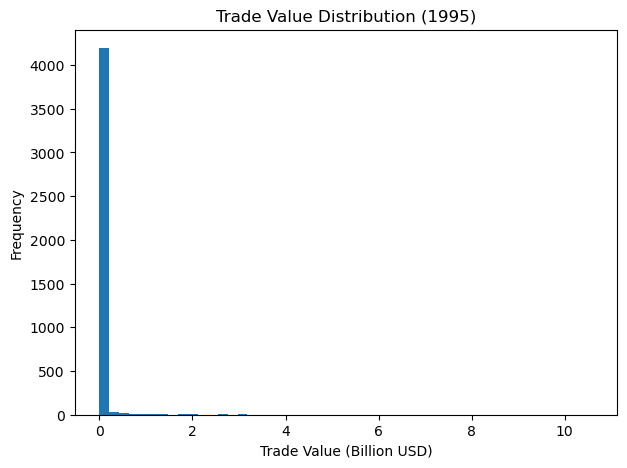


Top 25 Most Central Countries


,Country,Degree,PageRank
17,USA,266,0.168
91,Singapore,169,0.069
9,Germany,238,0.054
32,Malaysia,144,0.053
26,"China, Hong Kong SAR",150,0.052
31,Japan,193,0.046
19,United Kingdom,252,0.044
80,"Other Asia, nes",114,0.041
38,Rep. of Korea,142,0.036
23,Canada,191,0.029




YEAR : 1996

Top 25 Exporters


exporter
USA                             33.284
Japan                           33.193
Rep. of Korea                   16.223
Malaysia                        16.117
Singapore                       12.889
Other Asia, nes                  9.896
Philippines                      8.820
Germany                          6.629
China, Hong Kong SAR             5.980
France                           5.582
United Kingdom                   5.182
Thailand                         3.460
Netherlands                      3.148
Canada                           2.984
Ireland                          1.796
Mexico                           1.688
China                            1.336
Italy                            1.197
Malta                            0.796
Austria                          0.608
Belgium-Luxembourg (...1998)     0.587
Switzerland                      0.529
Israel                           0.406
Sweden                           0.380
Morocco                          0.346
Name: Trade Valu


Top 25 Importers


importer
USA                             38.816
Singapore                       18.358
Japan                           13.058
China, Hong Kong SAR            12.693
Malaysia                        11.637
Other Asia, nes                 10.841
Rep. of Korea                    9.956
United Kingdom                   9.422
Germany                          7.974
Canada                           4.989
Thailand                         4.393
France                           4.281
Mexico                           3.776
China                            3.583
Philippines                      3.292
Italy                            3.283
Ireland                          1.450
Netherlands                      1.161
Sweden                           1.159
Belgium-Luxembourg (...1998)     1.120
Brazil                           0.951
Finland                          0.810
Malta                            0.787
Australia                        0.771
Spain                            0.715
Name: Trade Valu


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
6601,Japan,USA,8.579
7640,Rep. of Korea,USA,6.202
8638,USA,Japan,6.115
6785,Malaysia,USA,4.938
6587,Japan,Singapore,4.090
7452,Philippines,USA,3.894
6773,Malaysia,Singapore,3.715
8681,USA,Rep. of Korea,3.560
6551,Japan,Malaysia,3.386
7328,"Other Asia, nes",USA,2.991


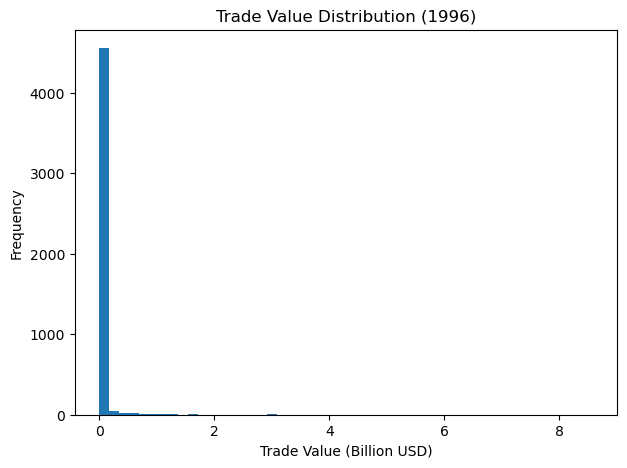


Top 25 Most Central Countries


,Country,Degree,PageRank
16,USA,280,0.166
42,Singapore,186,0.069
34,Japan,182,0.056
59,"China, Hong Kong SAR",153,0.051
8,Germany,256,0.048
35,Malaysia,149,0.048
51,United Kingdom,250,0.046
13,Rep. of Korea,159,0.046
38,"Other Asia, nes",124,0.043
7,France,236,0.030




YEAR : 1997

Top 25 Exporters


exporter
USA                             37.600
Japan                           33.165
Malaysia                        17.545
Rep. of Korea                   16.186
Singapore                       12.817
Other Asia, nes                 12.353
Philippines                     10.607
Germany                          7.077
France                           5.787
Netherlands                      5.383
United Kingdom                   4.987
China, Hong Kong SAR             4.621
Thailand                         4.053
Canada                           3.329
China                            2.026
Ireland                          1.875
Mexico                           1.340
Italy                            1.189
Austria                          0.756
Israel                           0.736
Malta                            0.686
Belgium-Luxembourg (...1998)     0.678
Sweden                           0.562
Switzerland                      0.507
Indonesia                        0.466
Name: Trade Valu


Top 25 Importers


importer
USA                             36.777
Singapore                       19.728
China, Hong Kong SAR            14.926
Malaysia                        13.102
Japan                           12.823
Rep. of Korea                   11.889
Other Asia, nes                 11.646
United Kingdom                   8.280
Germany                          8.205
Canada                           5.249
France                           5.179
Netherlands                      4.995
Philippines                      4.860
Thailand                         4.481
Mexico                           4.202
China                            4.190
Italy                            3.007
Ireland                          1.767
Sweden                           1.507
Belgium-Luxembourg (...1998)     1.329
Brazil                           1.145
Spain                            0.781
Finland                          0.734
Australia                        0.727
Denmark                          0.678
Name: Trade Valu


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
11419,Japan,USA,7.762
12563,Rep. of Korea,USA,5.990
13638,USA,Japan,5.736
11628,Malaysia,USA,5.181
13687,USA,Rep. of Korea,4.808
11615,Malaysia,Singapore,4.075
11405,Japan,Singapore,4.014
13699,USA,Singapore,3.825
12369,Philippines,USA,3.462
11367,Japan,Malaysia,3.410


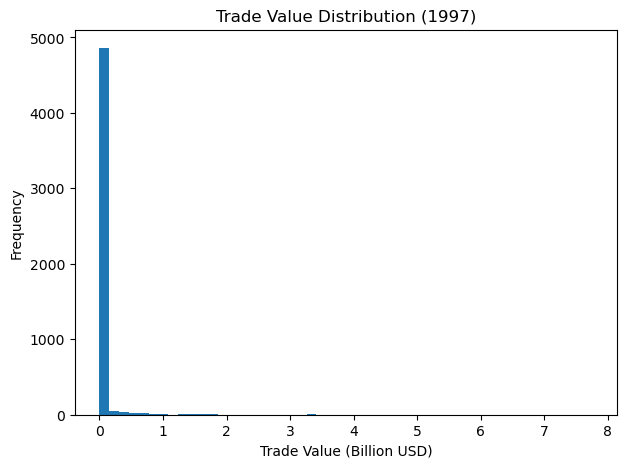


Top 25 Most Central Countries


,Country,Degree,PageRank
12,USA,300,0.155
44,Singapore,177,0.063
29,"China, Hong Kong SAR",153,0.052
37,Japan,206,0.051
38,Malaysia,148,0.047
43,Rep. of Korea,162,0.047
6,Germany,260,0.045
40,"Other Asia, nes",181,0.045
54,United Kingdom,237,0.040
5,France,238,0.034




YEAR : 1998

Top 25 Exporters


exporter
USA                             36.685
Japan                           29.248
Malaysia                        15.947
Rep. of Korea                   15.650
Philippines                     12.603
Other Asia, nes                 11.967
Singapore                       11.659
Germany                          7.604
France                           6.202
China, Hong Kong SAR             4.693
United Kingdom                   4.537
Netherlands                      4.265
Thailand                         3.543
Canada                           3.122
China                            2.349
Ireland                          1.609
Italy                            1.303
Mexico                           1.300
Malta                            0.971
Austria                          0.762
Belgium-Luxembourg (...1998)     0.629
Israel                           0.596
Morocco                          0.546
Indonesia                        0.531
Sweden                           0.527
Name: Trade Valu


Top 25 Importers


importer
USA                             34.110
Singapore                       17.905
Other Asia, nes                 13.126
Malaysia                        12.930
China, Hong Kong SAR            12.802
Rep. of Korea                   11.719
Japan                           11.034
Germany                          9.056
United Kingdom                   6.640
France                           6.042
China                            5.531
Canada                           5.276
Mexico                           5.066
Philippines                      4.976
Thailand                         3.266
Italy                            2.839
Ireland                          2.371
Netherlands                      1.762
Sweden                           1.420
Belgium-Luxembourg (...1998)     1.086
Brazil                           0.977
Malta                            0.967
Finland                          0.947
Spain                            0.886
Costa Rica                       0.860
Name: Trade Valu


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
16621,Japan,USA,5.894
19005,USA,Rep. of Korea,5.311
17847,Rep. of Korea,USA,5.307
18958,USA,Japan,4.546
16844,Malaysia,USA,4.524
18979,USA,Mexico,4.096
17650,Philippines,USA,3.961
16831,Malaysia,Singapore,3.948
19019,USA,Singapore,3.445
18994,USA,"Other Asia, nes",3.179


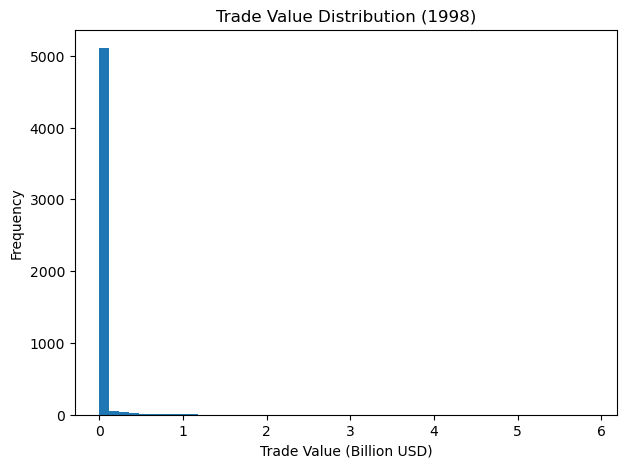


Top 25 Most Central Countries


,Country,Degree,PageRank
26,USA,295,0.152
44,Singapore,175,0.058
6,Germany,260,0.054
38,"Other Asia, nes",185,0.047
31,"China, Hong Kong SAR",162,0.047
89,Malaysia,159,0.046
43,Rep. of Korea,164,0.046
82,Japan,203,0.044
5,France,249,0.040
47,United Kingdom,250,0.036




YEAR : 1999

Top 25 Exporters


exporter
USA                     42.757
Japan                   34.328
Malaysia                18.396
Rep. of Korea           18.313
Other Asia, nes         15.268
Singapore               15.268
Philippines             14.038
Germany                  7.893
France                   6.307
China, Hong Kong SAR     5.642
United Kingdom           5.200
Netherlands              4.390
Thailand                 4.250
China                    3.936
Canada                   2.766
Ireland                  2.110
Mexico                   1.931
Italy                    1.274
Switzerland              1.072
Malta                    0.967
Austria                  0.803
Belgium                  0.690
Morocco                  0.645
Israel                   0.631
Indonesia                0.579
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
USA                     38.227
Singapore               21.319
Malaysia                16.391
Other Asia, nes         15.218
China, Hong Kong SAR    15.142
Rep. of Korea           15.129
Japan                   13.261
Germany                  9.373
China                    8.710
United Kingdom           7.484
Mexico                   6.872
France                   5.888
Canada                   5.516
Philippines              5.300
Thailand                 5.099
Ireland                  2.931
Italy                    2.781
Netherlands              1.497
Belgium                  1.374
Sweden                   1.329
Brazil                   1.312
Finland                  1.069
Malta                    0.992
Spain                    0.920
Austria                  0.793
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
24705,USA,Rep. of Korea,6.935
22078,Japan,USA,6.651
23481,Rep. of Korea,USA,6.539
24678,USA,Mexico,5.618
22398,Malaysia,USA,5.241
22382,Malaysia,Singapore,4.922
24656,USA,Japan,4.465
23264,Philippines,USA,4.391
22062,Japan,Singapore,3.804
23752,Singapore,Malaysia,3.786


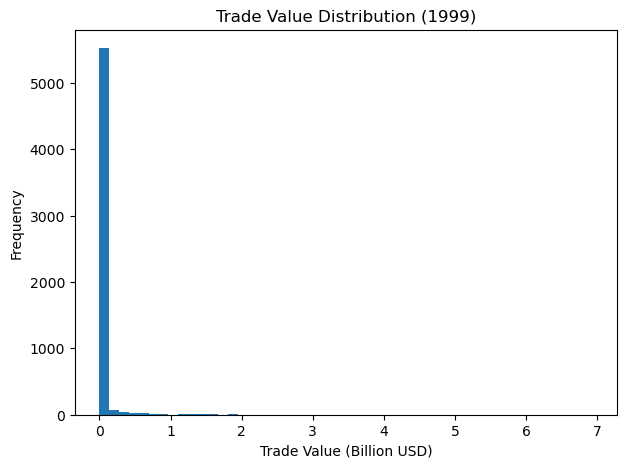


Top 25 Most Central Countries


,Country,Degree,PageRank
8,USA,307,0.149
42,Singapore,203,0.066
36,Malaysia,201,0.059
17,Rep. of Korea,195,0.051
37,"Other Asia, nes",198,0.048
79,Japan,206,0.047
30,"China, Hong Kong SAR",159,0.046
7,Germany,280,0.044
11,France,257,0.034
15,United Kingdom,268,0.034




YEAR : 2000

Top 25 Exporters


exporter
USA                     54.663
Japan                   45.759
Rep. of Korea           24.200
Malaysia                22.475
Other Asia, nes         20.221
Singapore               19.259
Philippines             18.210
Germany                 10.689
China, Hong Kong SAR     7.161
France                   6.995
United Kingdom           6.826
Thailand                 5.302
China                    5.085
Netherlands              4.973
Canada                   3.495
Mexico                   2.579
Ireland                  2.522
Italy                    2.288
Switzerland              1.691
Malta                    1.304
Israel                   1.292
Belgium                  1.229
Austria                  1.031
Indonesia                0.965
Sweden                   0.962
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
USA                     43.774
Singapore               30.216
Other Asia, nes         21.064
China, Hong Kong SAR    20.979
Rep. of Korea           17.692
Malaysia                17.325
Japan                   16.760
China                   13.292
Germany                 12.532
United Kingdom          10.953
Mexico                  10.369
France                   9.122
Canada                   7.474
Philippines              6.311
Thailand                 5.414
Italy                    3.627
Ireland                  3.124
Belgium                  2.649
Brazil                   2.081
Sweden                   2.003
Netherlands              1.910
Malta                    1.541
Israel                   1.509
Hungary                  1.381
Finland                  1.293
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
28417,Japan,USA,8.461
31584,USA,Mexico,8.362
30121,Rep. of Korea,USA,7.324
28780,Malaysia,Singapore,7.037
31613,USA,Rep. of Korea,7.015
31561,USA,Japan,5.467
29845,Philippines,USA,5.439
28403,Japan,Singapore,5.245
31626,USA,Singapore,4.635
29538,"Other Asia, nes","China, Hong Kong SAR",4.397


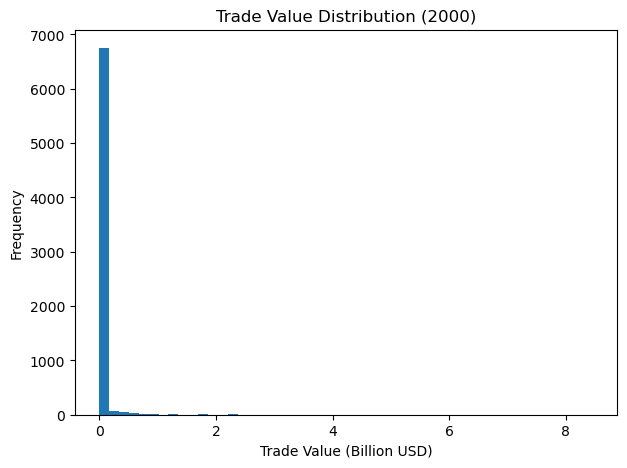


Top 25 Most Central Countries


,Country,Degree,PageRank
14,USA,323,0.138
29,Singapore,228,0.071
46,"China, Hong Kong SAR",172,0.051
8,Rep. of Korea,231,0.048
60,"Other Asia, nes",218,0.048
58,Malaysia,192,0.047
5,Germany,287,0.046
23,Japan,233,0.045
12,France,299,0.041
20,United Kingdom,284,0.037




YEAR : 2001

Top 25 Exporters


exporter
USA                     42.706
Japan                   34.668
Malaysia                20.812
Other Asia, nes         18.661
Philippines             16.120
Rep. of Korea           15.975
Singapore               14.414
Germany                  9.319
United Kingdom           7.549
China, Hong Kong SAR     6.660
France                   5.600
China                    5.048
Thailand                 4.470
Netherlands              4.361
Canada                   2.557
Ireland                  2.485
Mexico                   1.760
Italy                    1.541
Switzerland              1.336
Malta                    1.309
Belgium                  1.267
Austria                  1.143
Israel                   0.878
Indonesia                0.687
Costa Rica               0.671
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
USA                     28.447
Singapore               24.385
China, Hong Kong SAR    18.414
China                   17.344
Other Asia, nes         15.408
Malaysia                14.533
Japan                   13.825
Rep. of Korea           13.531
Germany                 11.345
Mexico                   9.477
United Kingdom           8.495
Philippines              6.017
Thailand                 5.991
France                   5.260
Ireland                  4.727
Canada                   3.889
Italy                    3.051
Belgium                  2.094
Netherlands              1.972
Brazil                   1.739
Hungary                  1.628
Sweden                   1.180
Austria                  1.174
Costa Rica               1.013
Spain                    0.955
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
35934,Malaysia,Singapore,6.238
38880,USA,Mexico,5.723
35558,Japan,USA,4.736
38909,USA,Rep. of Korea,4.211
38860,USA,Japan,4.190
35452,Japan,China,4.091
36718,"Other Asia, nes","China, Hong Kong SAR",4.008
38924,USA,Singapore,3.669
35543,Japan,Singapore,3.587
37053,Philippines,USA,3.545


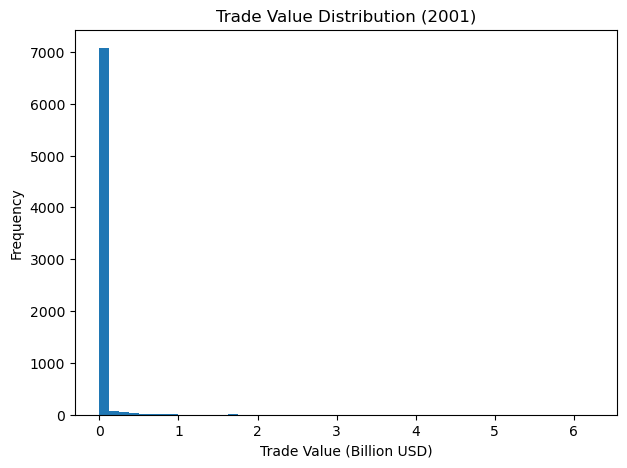


Top 25 Most Central Countries


,Country,Degree,PageRank
21,USA,323,0.115
19,Singapore,217,0.067
24,China,216,0.058
45,"China, Hong Kong SAR",180,0.056
56,Malaysia,212,0.055
30,Germany,299,0.051
58,"Other Asia, nes",220,0.045
32,Japan,221,0.045
26,Rep. of Korea,234,0.044
27,United Kingdom,293,0.038




YEAR : 2002

Top 25 Exporters


exporter
USA                     35.923
Japan                   34.366
Malaysia                24.803
Other Asia, nes         23.604
Rep. of Korea           18.831
Philippines             17.272
Singapore               13.756
Germany                  9.685
United Kingdom           8.915
China, Hong Kong SAR     7.982
China                    7.491
France                   5.095
Thailand                 4.747
Netherlands              3.798
Ireland                  2.272
Italy                    1.862
Malta                    1.732
Canada                   1.635
Mexico                   1.559
Costa Rica               1.380
Switzerland              1.165
Morocco                  1.086
Austria                  1.056
Indonesia                0.730
Portugal                 0.657
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China                   27.642
USA                     25.848
Singapore               25.045
China, Hong Kong SAR    21.294
Other Asia, nes         17.489
Malaysia                16.178
Rep. of Korea           14.940
Japan                   13.514
Germany                  9.793
Mexico                   7.480
Philippines              7.189
Ireland                  6.492
United Kingdom           6.171
France                   5.434
Thailand                 4.716
Canada                   2.662
Italy                    2.610
Hungary                  1.844
Netherlands              1.752
Brazil                   1.464
Belgium                  1.326
Czechia                  1.284
Costa Rica               1.223
Austria                  1.076
Portugal                 0.937
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
43298,Malaysia,Singapore,7.256
42784,Japan,China,6.299
44122,"Other Asia, nes",China,5.370
44123,"Other Asia, nes","China, Hong Kong SAR",5.300
46614,United Kingdom,Ireland,5.111
46347,USA,Rep. of Korea,4.665
40563,"China, Hong Kong SAR",China,4.398
43313,Malaysia,USA,4.140
46337,USA,"Other Asia, nes",4.049
42870,Japan,Rep. of Korea,3.906


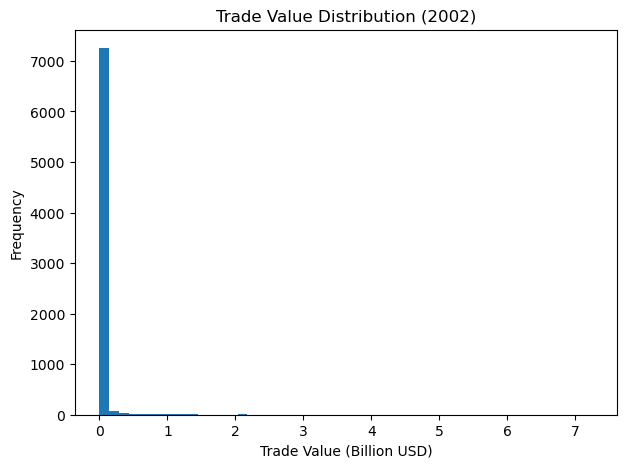


Top 25 Most Central Countries


,Country,Degree,PageRank
22,USA,318,0.098
49,China,229,0.083
3,"China, Hong Kong SAR",177,0.066
67,Singapore,228,0.066
17,Malaysia,217,0.059
18,"Other Asia, nes",232,0.050
34,Rep. of Korea,224,0.048
14,Germany,327,0.046
59,Japan,229,0.041
24,France,295,0.030




YEAR : 2003

Top 25 Exporters


exporter
Japan                   39.733
USA                     38.551
Malaysia                28.656
Other Asia, nes         27.208
Rep. of Korea           22.838
Philippines             22.381
Singapore               21.271
Germany                 12.254
China                   11.329
China, Hong Kong SAR     5.745
Thailand                 5.714
Netherlands              5.551
France                   5.249
United Kingdom           4.474
Costa Rica               3.122
Ireland                  2.389
Italy                    2.274
Malta                    1.994
Canada                   1.779
Mexico                   1.683
Switzerland              1.505
Indonesia                1.267
Austria                  1.217
Israel                   1.090
Portugal                 1.003
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China                   36.871
China, Hong Kong SAR    28.788
Singapore               27.807
USA                     22.452
Other Asia, nes         20.051
Malaysia                18.774
Rep. of Korea           17.931
Japan                   16.954
Germany                 13.443
Philippines              7.757
Mexico                   7.573
Netherlands              6.645
Thailand                 6.617
United Kingdom           6.482
France                   5.179
Italy                    2.826
Hungary                  2.711
Canada                   2.685
Ireland                  2.579
Brazil                   1.689
Czechia                  1.587
Belgium                  1.439
Finland                  1.378
Austria                  1.227
Portugal                 1.227
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
50411,Japan,China,8.804
50969,Malaysia,Singapore,7.501
51849,"Other Asia, nes",China,6.791
51850,"Other Asia, nes","China, Hong Kong SAR",5.610
54188,USA,Rep. of Korea,5.123
50885,Malaysia,China,4.987
50500,Japan,Rep. of Korea,4.862
50412,Japan,"China, Hong Kong SAR",4.738
52924,Singapore,Malaysia,4.544
54136,USA,Japan,3.882


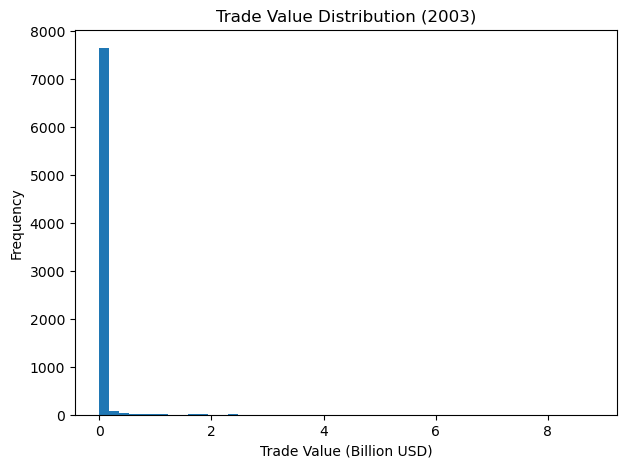


Top 25 Most Central Countries


,Country,Degree,PageRank
37,China,240,0.084
21,USA,325,0.079
8,Singapore,210,0.069
82,"China, Hong Kong SAR",199,0.067
113,Malaysia,222,0.059
13,Germany,312,0.054
18,"Other Asia, nes",235,0.053
7,Rep. of Korea,236,0.048
16,Japan,242,0.040
25,France,292,0.027




YEAR : 2004

Top 25 Exporters


exporter
Japan                   46.914
USA                     44.139
Other Asia, nes         35.222
Rep. of Korea           29.384
Malaysia                28.560
Singapore               25.453
Philippines             24.567
China                   17.982
Germany                 15.612
Netherlands              7.163
China, Hong Kong SAR     6.971
Thailand                 6.888
France                   6.511
United Kingdom           5.671
Costa Rica               3.281
Ireland                  3.090
Italy                    2.727
Malta                    2.564
Canada                   2.026
Mexico                   1.908
Switzerland              1.799
Austria                  1.710
Indonesia                1.580
Israel                   1.196
Morocco                  1.050
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China                   43.886
China, Hong Kong SAR    36.529
Singapore               36.164
USA                     24.173
Other Asia, nes         24.134
Malaysia                20.549
Rep. of Korea           19.486
Japan                   18.651
Germany                 17.161
Philippines              9.817
Mexico                   8.719
Netherlands              8.227
United Kingdom           7.967
Thailand                 7.835
France                   6.309
Hungary                  3.903
Canada                   3.567
Italy                    3.389
Ireland                  3.109
Brazil                   2.352
Czechia                  1.808
Portugal                 1.478
Spain                    1.462
Finland                  1.451
Belgium                  1.419
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
58514,Japan,China,10.300
60045,"Other Asia, nes",China,8.393
59086,Malaysia,Singapore,8.059
60046,"Other Asia, nes","China, Hong Kong SAR",7.352
62488,USA,Rep. of Korea,5.722
58515,Japan,"China, Hong Kong SAR",5.678
60145,"Other Asia, nes",Singapore,5.608
61177,Singapore,"China, Hong Kong SAR",5.504
60337,Philippines,China,5.202
60742,Rep. of Korea,"Other Asia, nes",5.014


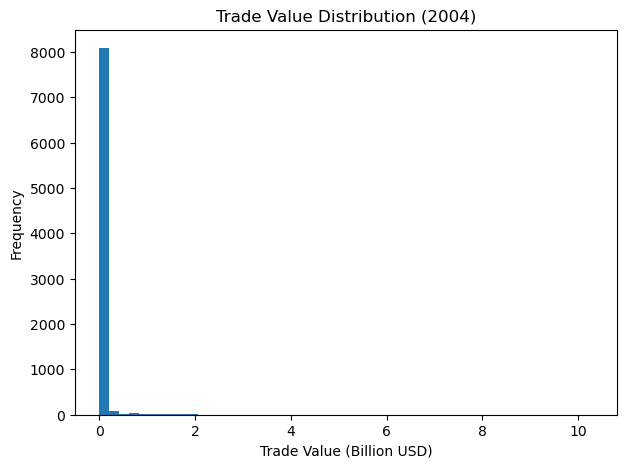


Top 25 Most Central Countries


,Country,Degree,PageRank
2,China,274,0.080
10,USA,333,0.077
7,Singapore,226,0.070
55,"China, Hong Kong SAR",199,0.069
3,Germany,318,0.059
16,"Other Asia, nes",246,0.049
69,Malaysia,202,0.047
42,Rep. of Korea,250,0.045
34,Japan,235,0.038
5,Mexico,253,0.028




YEAR : 2005

Top 25 Exporters


exporter
Japan                   46.355
Other Asia, nes         45.700
USA                     39.811
Rep. of Korea           32.785
Malaysia                31.696
Singapore               29.064
Philippines             25.469
China                   23.785
Germany                 15.315
Thailand                 7.741
Netherlands              7.119
France                   6.971
China, Hong Kong SAR     6.282
United Kingdom           5.864
Ireland                  3.518
Italy                    3.238
Canada                   2.593
Costa Rica               2.527
Mexico                   1.830
Malta                    1.714
Austria                  1.603
Indonesia                1.543
Morocco                  1.534
Israel                   1.253
Switzerland              1.201
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China                   64.226
China, Hong Kong SAR    41.953
Singapore               28.099
USA                     26.175
Other Asia, nes         26.156
Malaysia                21.089
Rep. of Korea           20.684
Japan                   18.868
Germany                 17.424
Mexico                   9.887
Philippines              8.836
Thailand                 7.664
United Kingdom           7.055
France                   6.772
Netherlands              6.650
Canada                   4.086
Hungary                  3.916
Italy                    3.314
Brazil                   2.699
Ireland                  2.606
Czechia                  1.875
Belgium                  1.845
Portugal                 1.725
Finland                  1.692
Spain                    1.597
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
68447,"Other Asia, nes",China,15.884
66901,Japan,China,10.628
68448,"Other Asia, nes","China, Hong Kong SAR",8.733
67426,Malaysia,China,7.956
68722,Philippines,China,7.692
64230,China,"China, Hong Kong SAR",6.452
69578,Singapore,"China, Hong Kong SAR",6.396
69056,Rep. of Korea,China,6.365
69128,Rep. of Korea,"Other Asia, nes",6.059
67507,Malaysia,Singapore,5.951


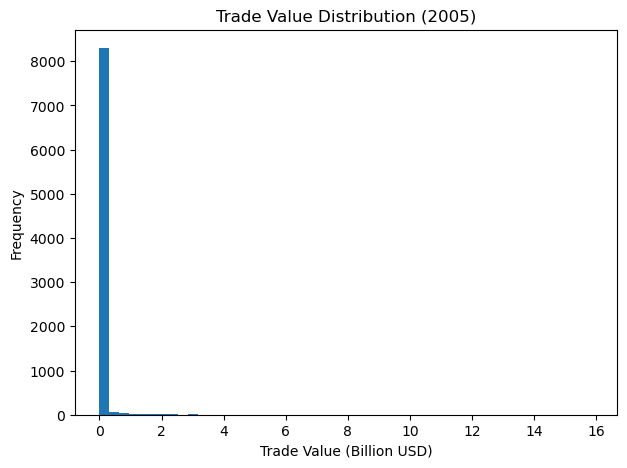


Top 25 Most Central Countries


,Country,Degree,PageRank
3,China,280,0.101
26,USA,340,0.083
59,"China, Hong Kong SAR",218,0.072
13,Singapore,219,0.057
17,Germany,317,0.055
20,"Other Asia, nes",247,0.050
42,Rep. of Korea,244,0.046
11,Mexico,300,0.042
73,Malaysia,185,0.042
10,Japan,236,0.035




YEAR : 2006

Top 25 Exporters


exporter
Other Asia, nes         52.544
Japan                   49.643
USA                     44.813
Rep. of Korea           44.399
Singapore               33.312
China                   32.190
Malaysia                29.415
Philippines             28.067
Germany                 16.446
Thailand                 9.200
France                   7.038
Netherlands              6.670
China, Hong Kong SAR     5.896
United Kingdom           5.744
Ireland                  3.537
Italy                    3.432
Costa Rica               2.405
Canada                   2.158
Mexico                   2.016
Austria                  1.954
Malta                    1.673
Portugal                 1.472
Israel                   1.332
Indonesia                1.308
Morocco                  1.192
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China                   72.948
China, Hong Kong SAR    49.821
Singapore               33.509
Other Asia, nes         28.926
USA                     25.028
Rep. of Korea           23.482
Malaysia                23.254
Japan                   22.513
Germany                 20.406
Philippines             12.280
Mexico                  10.401
Thailand                 9.383
France                   6.636
United Kingdom           5.916
Netherlands              5.859
Hungary                  3.966
Canada                   3.735
Italy                    3.660
Brazil                   3.295
Spain                    2.410
Belgium                  2.118
Czechia                  1.996
Costa Rica               1.873
Ireland                  1.773
Austria                  1.754
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
77913,Rep. of Korea,China,13.233
75627,Japan,China,12.741
77282,"Other Asia, nes",China,12.199
77283,"Other Asia, nes","China, Hong Kong SAR",10.759
77581,Philippines,China,10.701
78470,Singapore,"China, Hong Kong SAR",8.698
72807,China,"China, Hong Kong SAR",8.219
77332,"Other Asia, nes",Japan,6.705
76271,Malaysia,Singapore,6.584
77988,Rep. of Korea,"Other Asia, nes",6.400


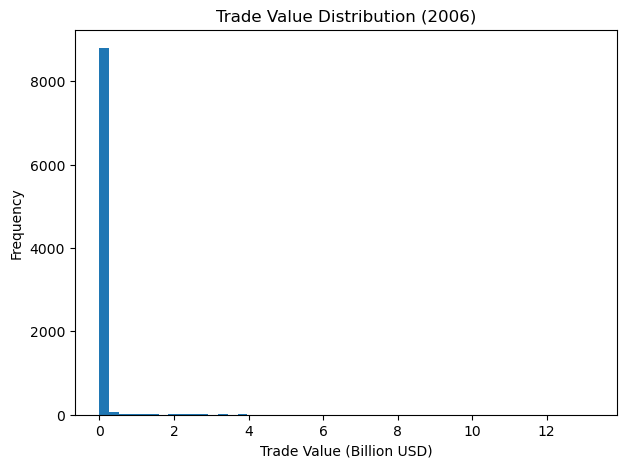


Top 25 Most Central Countries


,Country,Degree,PageRank
4,China,295,0.098
52,"China, Hong Kong SAR",228,0.074
25,USA,340,0.071
34,Singapore,241,0.063
5,Germany,321,0.058
38,Malaysia,235,0.050
19,"Other Asia, nes",271,0.048
20,Rep. of Korea,257,0.043
64,Japan,239,0.036
7,Mexico,319,0.035




YEAR : 2007

Top 25 Exporters


exporter
Other Asia, nes         87.279
Japan                   55.929
Rep. of Korea           49.803
USA                     47.942
Malaysia                45.311
Philippines             42.933
Singapore               40.440
China                   38.515
Germany                 18.709
Thailand                11.301
France                   7.437
Netherlands              7.343
China, Hong Kong SAR     6.877
United Kingdom           5.148
Ireland                  4.274
Italy                    3.753
Costa Rica               3.094
Austria                  3.088
Malta                    2.212
Canada                   2.172
Mexico                   1.974
Indonesia                1.841
Morocco                  1.417
Israel                   1.396
Switzerland              1.323
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China                   109.810
China, Hong Kong SAR     70.792
Singapore                54.869
USA                      29.461
Japan                    28.799
Other Asia, nes          28.649
Rep. of Korea            27.756
Malaysia                 24.126
Germany                  21.663
Philippines              15.406
Thailand                 10.825
France                    7.670
Mexico                    7.185
United Kingdom            5.776
Netherlands               5.563
Spain                     4.841
Hungary                   4.052
Italy                     4.006
Brazil                    3.552
Canada                    3.544
Belgium                   2.438
Czechia                   2.322
Portugal                  2.220
Finland                   1.872
Sweden                    1.839
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
86414,"Other Asia, nes",China,27.713
86415,"Other Asia, nes","China, Hong Kong SAR",19.873
86725,Philippines,China,17.189
87087,Rep. of Korea,China,15.704
84723,Japan,China,15.326
85362,Malaysia,Singapore,12.232
87675,Singapore,"China, Hong Kong SAR",11.747
85279,Malaysia,China,11.163
81835,China,"China, Hong Kong SAR",10.544
86521,"Other Asia, nes",Singapore,10.424


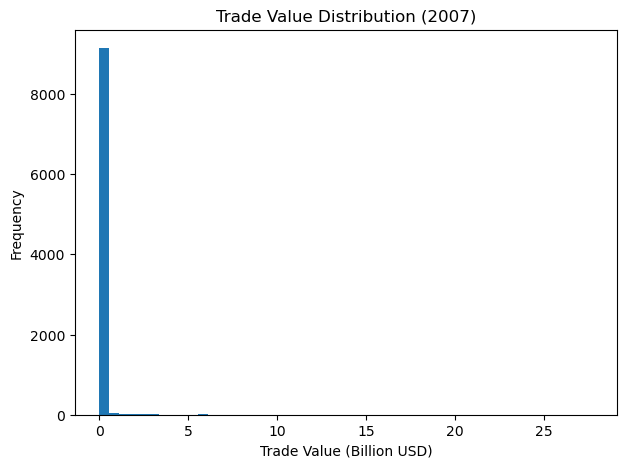


Top 25 Most Central Countries


,Country,Degree,PageRank
2,China,323,0.118
69,"China, Hong Kong SAR",224,0.080
56,Singapore,247,0.067
24,USA,346,0.060
80,Germany,319,0.052
21,"Other Asia, nes",276,0.046
17,Malaysia,235,0.046
50,Rep. of Korea,256,0.044
60,Japan,233,0.035
29,France,320,0.027




YEAR : 2008

Top 25 Exporters


exporter
Other Asia, nes         86.880
Japan                   54.891
Rep. of Korea           48.198
China                   47.263
Singapore               45.254
USA                     45.167
Malaysia                39.710
Philippines             37.589
Germany                 21.489
Thailand                10.696
France                   7.101
Netherlands              6.135
China, Hong Kong SAR     5.674
Ireland                  5.001
United Kingdom           4.923
Italy                    3.669
Austria                  3.153
Costa Rica               2.794
Malta                    2.642
Canada                   2.284
Mexico                   1.823
Czechia                  1.573
Indonesia                1.464
Switzerland              1.416
Belgium                  1.244
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China                   106.385
China, Hong Kong SAR     71.514
Singapore                54.345
Rep. of Korea            31.915
Other Asia, nes          27.180
USA                      27.032
Japan                    25.082
Germany                  22.250
Malaysia                 20.752
Philippines              12.525
Mexico                   10.493
Spain                    10.080
Thailand                  9.417
France                    7.641
United Kingdom            5.067
Italy                     4.847
Hungary                   4.598
Brazil                    4.156
Netherlands               3.769
Canada                    3.713
Indonesia                 2.878
Czechia                   2.705
Belgium                   2.636
Portugal                  2.106
Sweden                    1.958
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
95865,"Other Asia, nes",China,27.750
95866,"Other Asia, nes","China, Hong Kong SAR",19.147
96541,Rep. of Korea,China,16.264
94094,Japan,China,14.642
96173,Philippines,China,14.346
97126,Singapore,"China, Hong Kong SAR",13.472
91125,China,"China, Hong Kong SAR",12.203
95972,"Other Asia, nes",Singapore,10.776
94759,Malaysia,Singapore,10.468
94680,Malaysia,China,10.075


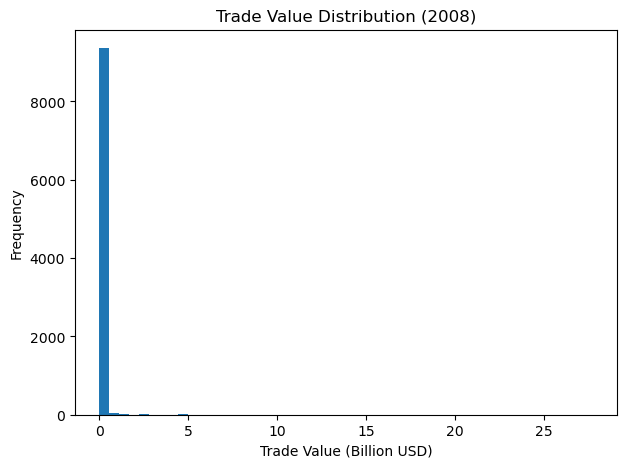


Top 25 Most Central Countries


,Country,Degree,PageRank
3,China,332,0.116
71,"China, Hong Kong SAR",241,0.077
33,Singapore,250,0.067
37,USA,350,0.061
22,Germany,308,0.054
10,Rep. of Korea,254,0.046
53,"Other Asia, nes",275,0.040
26,Malaysia,222,0.038
5,Japan,228,0.031
21,France,311,0.026




YEAR : 2009

Top 25 Exporters


exporter
Other Asia, nes         64.684
China                   46.016
Japan                   45.173
Rep. of Korea           43.745
Malaysia                38.163
Singapore               38.063
USA                     35.407
Philippines             24.177
Germany                 15.094
Thailand                10.128
Netherlands              6.338
France                   5.775
China, Hong Kong SAR     4.204
United Kingdom           3.547
Israel                   3.459
Costa Rica               3.032
Ireland                  2.998
Italy                    2.473
Austria                  2.136
Canada                   2.036
Mexico                   1.880
Malta                    1.687
Czechia                  1.493
Indonesia                1.181
Switzerland              1.170
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China                   91.576
China, Hong Kong SAR    58.250
Singapore               42.647
Rep. of Korea           26.113
Japan                   22.805
Other Asia, nes         22.624
Germany                 20.732
USA                     20.422
Malaysia                19.135
Philippines              9.487
Thailand                 8.854
Mexico                   8.356
France                   5.835
Italy                    4.906
Hungary                  3.709
Netherlands              3.704
Czechia                  3.440
Canada                   3.219
Brazil                   3.189
United Kingdom           3.157
Belgium                  2.919
India                    2.602
Spain                    2.249
Indonesia                2.146
Sweden                   2.081
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
105494,"Other Asia, nes",China,24.082
106179,Rep. of Korea,China,15.235
100671,China,"China, Hong Kong SAR",14.119
104266,Malaysia,China,13.157
103666,Japan,China,12.834
106816,Singapore,"China, Hong Kong SAR",12.334
105600,"Other Asia, nes",Singapore,8.025
106277,Rep. of Korea,Singapore,7.948
105495,"Other Asia, nes","China, Hong Kong SAR",7.670
105541,"Other Asia, nes",Japan,7.647


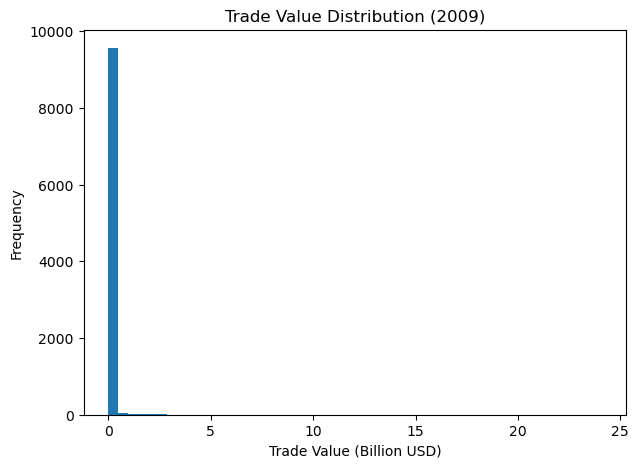


Top 25 Most Central Countries


,Country,Degree,PageRank
3,China,347,0.124
71,"China, Hong Kong SAR",247,0.082
7,Germany,330,0.061
20,USA,346,0.056
88,Singapore,249,0.056
16,Rep. of Korea,267,0.042
31,Malaysia,246,0.039
14,"Other Asia, nes",286,0.037
78,Japan,223,0.030
6,France,319,0.028




YEAR : 2010

Top 25 Exporters


exporter
China                   71.496
Other Asia, nes         68.473
Rep. of Korea           62.792
Japan                   55.912
Singapore               54.563
Malaysia                53.474
USA                     45.508
Philippines             30.255
Germany                 20.470
Thailand                14.037
Netherlands              7.382
France                   6.950
Costa Rica               5.794
China, Hong Kong SAR     5.353
United Kingdom           4.175
Italy                    3.407
Austria                  3.042
Mexico                   2.482
Ireland                  2.450
Israel                   2.233
Czechia                  2.021
Malta                    1.920
Canada                   1.772
Spain                    1.761
Switzerland              1.478
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China                   106.844
China, Hong Kong SAR     81.487
Singapore                55.004
Germany                  33.685
Other Asia, nes          32.709
USA                      28.938
Rep. of Korea            28.423
Japan                    24.083
Malaysia                 23.932
Italy                    14.683
Thailand                 12.511
Philippines              11.582
Mexico                   10.984
France                    9.501
Netherlands               6.061
Brazil                    4.439
Czechia                   4.374
United Kingdom            4.320
Hungary                   4.223
Canada                    4.131
Sweden                    3.795
Spain                     3.382
India                     2.654
Belgium                   2.489
Poland                    2.478
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
116153,Rep. of Korea,China,22.036
114175,Malaysia,China,19.073
110410,China,"China, Hong Kong SAR",17.606
116766,Singapore,"China, Hong Kong SAR",17.180
115452,"Other Asia, nes","China, Hong Kong SAR",15.671
113515,Japan,China,15.256
115451,"Other Asia, nes",China,14.294
115558,"Other Asia, nes",Singapore,10.906
114263,Malaysia,Singapore,9.523
110441,China,Germany,9.417


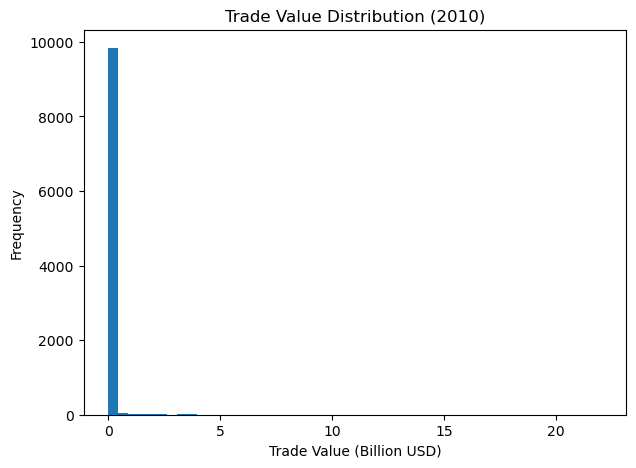


Top 25 Most Central Countries


,Country,Degree,PageRank
2,China,349,0.113
21,"China, Hong Kong SAR",258,0.075
24,Germany,299,0.064
48,USA,344,0.059
10,Singapore,263,0.056
25,Italy,263,0.041
9,Rep. of Korea,271,0.040
8,"Other Asia, nes",272,0.038
27,Malaysia,239,0.038
23,France,317,0.032




YEAR : 2011

Top 25 Exporters


exporter
China                   77.541
Other Asia, nes         68.122
Rep. of Korea           65.818
Malaysia                59.156
Singapore               54.581
Japan                   54.131
USA                     44.608
Philippines             22.478
Germany                 21.837
Thailand                13.030
Netherlands              9.322
Costa Rica               8.404
France                   7.462
China, Hong Kong SAR     5.009
United Kingdom           3.871
Italy                    3.822
Austria                  3.278
Ireland                  3.181
Mexico                   2.675
Czechia                  2.370
Canada                   2.255
Malta                    2.225
Spain                    1.562
Switzerland              1.546
Israel                   1.490
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China                   110.417
China, Hong Kong SAR     86.043
Singapore                54.429
USA                      36.367
Other Asia, nes          32.615
Germany                  31.215
Malaysia                 27.472
Rep. of Korea            25.301
Japan                    22.397
Italy                    12.574
Mexico                   12.148
France                   11.072
Thailand                  9.975
Netherlands               7.000
Philippines               5.628
United Kingdom            4.999
Brazil                    4.906
India                     4.294
Hungary                   4.160
Canada                    3.932
Czechia                   3.892
Belgium                   3.661
Sweden                    3.391
Viet Nam                  3.244
Poland                    2.404
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
126215,Rep. of Korea,China,23.313
124231,Malaysia,China,23.296
120415,China,"China, Hong Kong SAR",19.018
126862,Singapore,"China, Hong Kong SAR",18.111
123575,Japan,China,16.732
125495,"Other Asia, nes","China, Hong Kong SAR",16.410
125494,"Other Asia, nes",China,15.440
125605,"Other Asia, nes",Singapore,13.810
126309,Rep. of Korea,Singapore,9.833
126861,Singapore,China,9.058


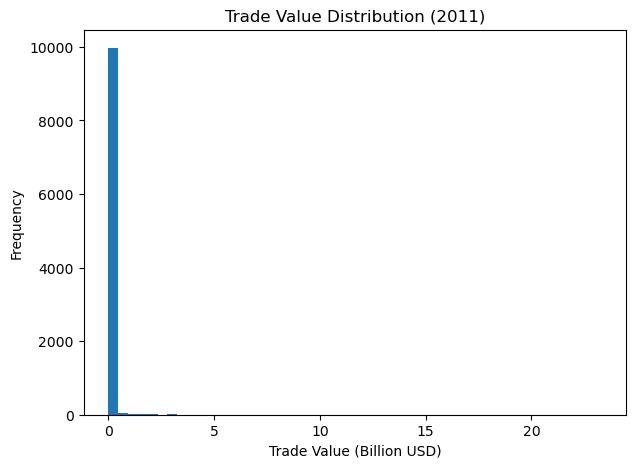


Top 25 Most Central Countries


,Country,Degree,PageRank
5,China,361,0.116
105,"China, Hong Kong SAR",263,0.077
30,USA,349,0.062
45,Germany,289,0.056
60,Singapore,269,0.055
22,Malaysia,231,0.044
48,Rep. of Korea,266,0.037
38,"Other Asia, nes",292,0.035
8,France,332,0.034
20,Italy,263,0.033




YEAR : 2012

Top 25 Exporters


exporter
Other Asia, nes         78.687
China                   72.338
Rep. of Korea           55.490
Japan                   51.430
Singapore               46.234
USA                     41.705
Malaysia                35.623
Philippines             25.161
Germany                 19.000
Costa Rica              10.965
Thailand                 9.882
Netherlands              7.537
France                   6.786
Viet Nam                 3.874
Italy                    3.820
China, Hong Kong SAR     3.718
United Kingdom           3.363
Ireland                  2.728
Mexico                   2.627
Austria                  2.575
Canada                   2.201
Israel                   2.191
Malta                    1.745
Czechia                  1.636
Sweden                   1.367
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China                   84.762
China, Hong Kong SAR    83.269
Singapore               56.903
USA                     35.718
Rep. of Korea           30.028
Other Asia, nes         29.989
Malaysia                24.715
Japan                   21.928
Germany                 20.805
Mexico                  12.742
Philippines              9.667
Thailand                 8.999
France                   7.798
Viet Nam                 7.560
Netherlands              5.691
Italy                    5.323
Brazil                   4.809
India                    4.011
United Kingdom           3.646
Czechia                  3.593
Canada                   3.135
Hungary                  2.906
Belgium                  2.363
Indonesia                2.362
Israel                   2.319
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
130566,China,"China, Hong Kong SAR",19.972
135772,"Other Asia, nes","China, Hong Kong SAR",17.811
137171,Singapore,"China, Hong Kong SAR",17.678
133825,Japan,China,16.518
136534,Rep. of Korea,China,16.428
135883,"Other Asia, nes",Singapore,16.320
135771,"Other Asia, nes",China,14.114
136628,Rep. of Korea,Singapore,10.462
134580,Malaysia,Singapore,8.318
136535,Rep. of Korea,"China, Hong Kong SAR",7.920


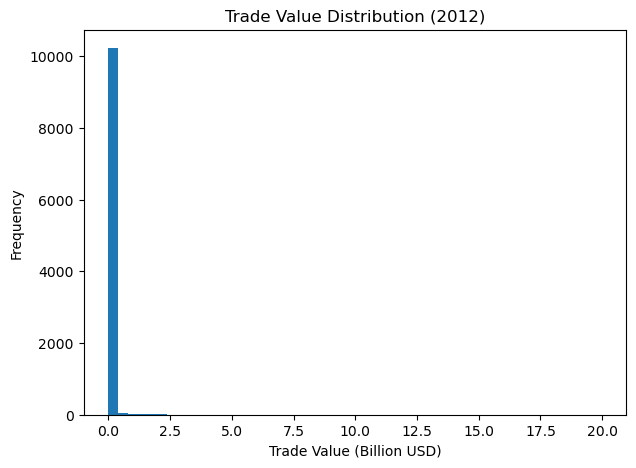


Top 25 Most Central Countries


,Country,Degree,PageRank
4,China,355,0.105
54,"China, Hong Kong SAR",268,0.084
46,USA,345,0.065
65,Singapore,280,0.062
89,Malaysia,227,0.049
25,Germany,312,0.046
58,Rep. of Korea,264,0.043
50,"Other Asia, nes",282,0.038
9,Mexico,298,0.029
8,Japan,231,0.024




YEAR : 2013

Top 25 Exporters


exporter
Other Asia, nes         92.069
China                   76.744
Rep. of Korea           62.354
Malaysia                57.461
Singapore               49.262
Japan                   47.904
USA                     47.860
Philippines             24.825
Germany                 18.418
Costa Rica              12.409
Thailand                10.528
Netherlands              6.903
France                   6.203
Viet Nam                 4.150
Israel                   3.804
Italy                    3.411
United Kingdom           3.317
Ireland                  2.860
Mexico                   2.813
Austria                  2.747
China, Hong Kong SAR     2.643
Canada                   2.001
Czechia                  1.450
Switzerland              1.241
Malta                    1.232
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China                   115.024
China, Hong Kong SAR     92.961
Singapore                62.747
USA                      34.807
Rep. of Korea            32.823
Malaysia                 29.686
Other Asia, nes          28.922
Japan                    25.103
Germany                  18.620
Mexico                   12.566
Viet Nam                 10.507
Philippines              10.313
Thailand                  9.663
France                    7.323
Netherlands               5.645
Brazil                    5.327
United Kingdom            3.753
India                     3.466
Canada                    3.449
Czechia                   3.240
Italy                     3.094
Hungary                   2.809
Israel                    2.148
Indonesia                 2.052
Poland                    1.955
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
144957,Malaysia,China,24.086
140955,China,"China, Hong Kong SAR",21.915
147055,Rep. of Korea,China,20.382
146306,"Other Asia, nes","China, Hong Kong SAR",19.982
146419,"Other Asia, nes",Singapore,19.641
147701,Singapore,"China, Hong Kong SAR",18.144
146305,"Other Asia, nes",China,16.784
144253,Japan,China,15.146
149207,USA,China,11.934
147150,Rep. of Korea,Singapore,11.096


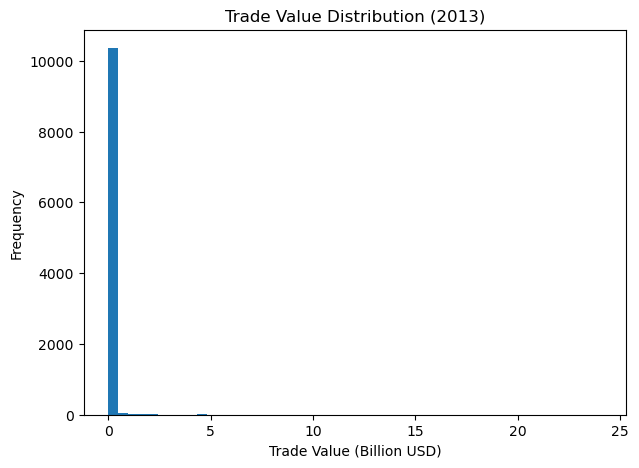


Top 25 Most Central Countries


,Country,Degree,PageRank
3,China,369,0.122
79,"China, Hong Kong SAR",273,0.089
77,Singapore,281,0.064
34,USA,339,0.055
45,Rep. of Korea,271,0.050
26,Malaysia,243,0.046
5,Germany,316,0.043
13,"Other Asia, nes",282,0.037
61,Japan,251,0.030
8,Mexico,310,0.025




YEAR : 2014

Top 25 Exporters


exporter
Other Asia, nes         105.810
China                    88.471
Malaysia                 62.834
Rep. of Korea            61.711
Singapore                52.020
USA                      45.991
Japan                    45.755
Germany                  20.114
Philippines              13.943
Thailand                 11.594
Netherlands               6.818
France                    6.425
Costa Rica                5.830
Viet Nam                  5.033
Israel                    4.282
China, Hong Kong SAR      3.370
Mexico                    3.270
United Kingdom            3.209
Austria                   2.965
Italy                     2.861
Canada                    1.992
Czechia                   1.392
Malta                     1.322
Ireland                   1.158
Switzerland               1.149
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China                   112.512
China, Hong Kong SAR    109.411
Singapore                56.336
Rep. of Korea            33.648
USA                      33.008
Malaysia                 31.539
Other Asia, nes          30.941
Japan                    26.742
Germany                  20.729
Mexico                   14.173
Viet Nam                 10.841
Philippines              10.070
Thailand                  9.956
France                    6.771
Netherlands               6.197
United Kingdom            5.071
Brazil                    5.003
Czechia                   3.615
Hungary                   3.044
India                     2.972
Canada                    2.898
Poland                    2.779
Italy                     2.327
Indonesia                 2.053
Israel                    1.987
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
151478,China,"China, Hong Kong SAR",28.666
157503,Rep. of Korea,China,24.500
156741,"Other Asia, nes","China, Hong Kong SAR",24.488
155450,Malaysia,China,21.824
156856,"Other Asia, nes",Singapore,21.657
158175,Singapore,"China, Hong Kong SAR",20.716
156740,"Other Asia, nes",China,20.123
154752,Japan,China,14.002
157504,Rep. of Korea,"China, Hong Kong SAR",10.464
159738,USA,China,10.395


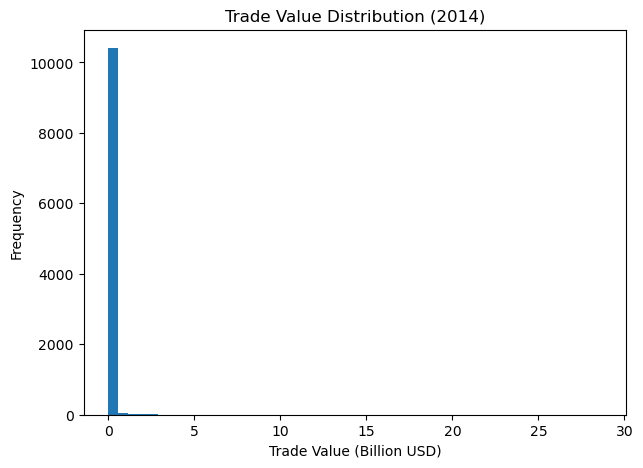


Top 25 Most Central Countries


,Country,Degree,PageRank
5,China,364,0.112
85,"China, Hong Kong SAR",256,0.092
67,Singapore,300,0.056
16,USA,345,0.055
12,Rep. of Korea,277,0.050
24,Malaysia,245,0.049
20,Germany,314,0.048
10,"Other Asia, nes",271,0.036
95,Japan,245,0.028
8,France,330,0.024




YEAR : 2015

Top 25 Exporters


exporter
Other Asia, nes         100.736
China                    95.229
Rep. of Korea            70.451
Malaysia                 64.366
Singapore                46.463
Japan                    43.940
USA                      42.918
Philippines              23.505
Germany                  18.490
Thailand                 11.843
Viet Nam                 10.619
Netherlands               5.786
Israel                    5.342
France                    5.145
Mexico                    3.915
China, Hong Kong SAR      2.963
United Kingdom            2.909
Italy                     2.536
Austria                   2.422
Ireland                   1.986
Canada                    1.569
Czechia                   1.388
Switzerland               1.093
Malta                     1.029
Costa Rica                1.021
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China                   117.027
China, Hong Kong SAR    115.898
Singapore                56.435
USA                      38.620
Rep. of Korea            35.606
Other Asia, nes          29.742
Malaysia                 28.047
Japan                    25.331
Germany                  17.958
Mexico                   16.254
Viet Nam                 13.431
Thailand                  9.348
Philippines               9.000
France                    6.388
Netherlands               4.967
United Kingdom            4.713
India                     4.194
Brazil                    3.426
Czechia                   2.951
Hungary                   2.853
Canada                    2.704
Israel                    2.662
Poland                    2.538
Italy                     2.163
Indonesia                 1.853
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
162123,China,"China, Hong Kong SAR",32.831
168318,Rep. of Korea,China,26.513
167537,"Other Asia, nes","China, Hong Kong SAR",22.967
166195,Malaysia,China,21.672
168977,Singapore,"China, Hong Kong SAR",19.950
167536,"Other Asia, nes",China,18.714
167646,"Other Asia, nes",Singapore,18.418
165459,Japan,China,13.640
168319,Rep. of Korea,"China, Hong Kong SAR",11.993
166310,Malaysia,USA,11.985


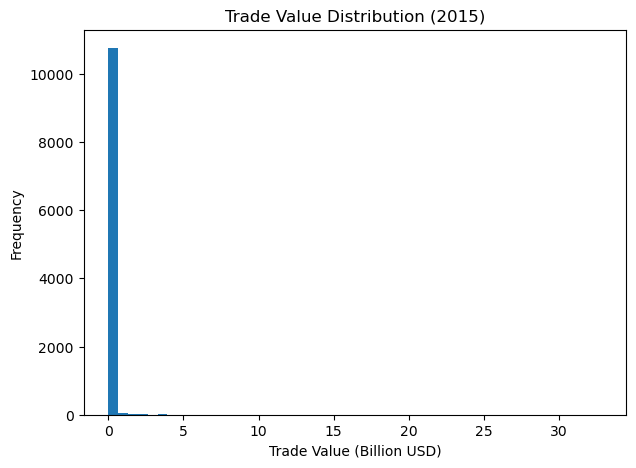


Top 25 Most Central Countries


,Country,Degree,PageRank
2,China,365,0.116
117,"China, Hong Kong SAR",262,0.100
30,USA,349,0.067
75,Singapore,294,0.055
100,Rep. of Korea,275,0.050
22,Malaysia,242,0.049
20,Germany,318,0.043
9,"Other Asia, nes",269,0.034
5,France,334,0.024
7,Japan,249,0.024




YEAR : 2016

Top 25 Exporters


exporter
Other Asia, nes         109.883
China                    96.439
Rep. of Korea            72.979
Malaysia                 67.109
Japan                    48.149
Singapore                45.551
USA                      44.168
Philippines              24.973
Germany                  17.485
Viet Nam                 14.803
Thailand                 13.185
Ireland                   7.537
France                    5.550
Netherlands               5.405
Mexico                    3.949
Israel                    3.480
United Kingdom            3.229
China, Hong Kong SAR      3.205
Italy                     2.411
Austria                   2.290
Czechia                   1.505
Canada                    1.473
Switzerland               0.994
Indonesia                 0.919
Morocco                   0.896
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China, Hong Kong SAR    130.515
China                   117.330
Singapore                56.907
USA                      43.926
Rep. of Korea            33.870
Other Asia, nes          32.741
Malaysia                 26.622
Japan                    23.025
Germany                  19.125
Viet Nam                 17.119
Mexico                   16.200
Philippines              12.847
Thailand                 10.794
Netherlands               6.334
France                    5.844
India                     5.381
United Kingdom            3.401
Hungary                   3.087
Brazil                    3.036
Israel                    2.912
TÃ¼rkiye                  2.792
Czechia                   2.742
Poland                    2.467
Canada                    2.303
Italy                     2.257
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
173078,China,"China, Hong Kong SAR",35.499
178605,"Other Asia, nes","China, Hong Kong SAR",26.527
178604,"Other Asia, nes",China,23.996
179395,Rep. of Korea,China,22.893
180073,Singapore,"China, Hong Kong SAR",22.688
177273,Malaysia,China,20.472
178722,"Other Asia, nes",Singapore,17.136
179396,Rep. of Korea,"China, Hong Kong SAR",15.500
177395,Malaysia,USA,13.996
176519,Japan,China,13.822


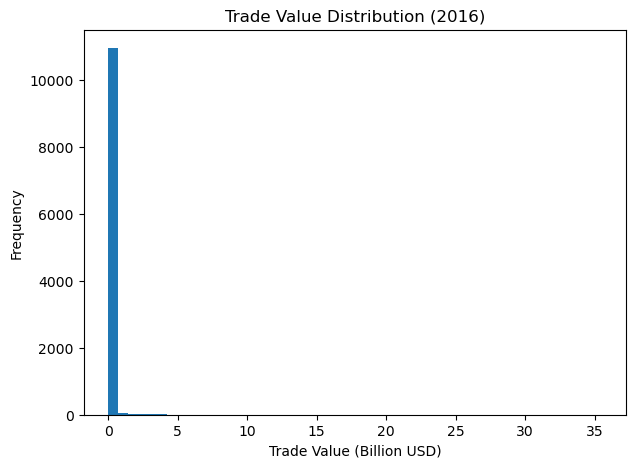


Top 25 Most Central Countries


,Country,Degree,PageRank
90,"China, Hong Kong SAR",275,0.105
2,China,378,0.103
12,USA,345,0.065
58,Singapore,306,0.056
22,Malaysia,249,0.048
55,Rep. of Korea,287,0.047
19,Germany,318,0.044
80,"Other Asia, nes",267,0.034
25,Philippines,226,0.026
18,France,350,0.022




YEAR : 2017

Top 25 Exporters


exporter
Other Asia, nes         168.087
Singapore               125.144
Rep. of Korea           120.040
China                   114.209
Malaysia                 78.924
Japan                    44.319
USA                      43.964
Philippines              40.256
Viet Nam                 23.628
Germany                  20.141
Thailand                 15.707
Ireland                   8.671
Mexico                    6.925
Netherlands               6.779
France                    5.463
China, Hong Kong SAR      3.831
United Kingdom            3.657
Israel                    2.688
Italy                     2.617
Austria                   2.040
Canada                    1.344
Indonesia                 1.258
Czechia                   1.001
Switzerland               0.987
Malta                     0.871
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China                   209.434
China, Hong Kong SAR    184.677
Singapore                66.808
USA                      50.013
Other Asia, nes          48.294
Rep. of Korea            43.425
Malaysia                 38.801
Japan                    28.779
Viet Nam                 26.424
Germany                  22.774
Mexico                   20.429
Netherlands              15.610
Thailand                 13.866
Philippines              12.822
India                     7.699
France                    6.576
Brazil                    5.254
Czechia                   3.852
Hungary                   3.599
TÃ¼rkiye                  3.456
Poland                    3.184
United Kingdom            3.010
Canada                    2.670
Indonesia                 2.565
Italy                     2.561
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
189689,"Other Asia, nes",China,66.911
190489,Rep. of Korea,China,52.895
191209,Singapore,"China, Hong Kong SAR",49.308
184212,China,"China, Hong Kong SAR",42.277
189690,"Other Asia, nes","China, Hong Kong SAR",30.130
190490,Rep. of Korea,"China, Hong Kong SAR",21.787
189804,"Other Asia, nes",Singapore,21.516
191208,Singapore,China,21.095
188324,Malaysia,China,19.930
188442,Malaysia,USA,14.131


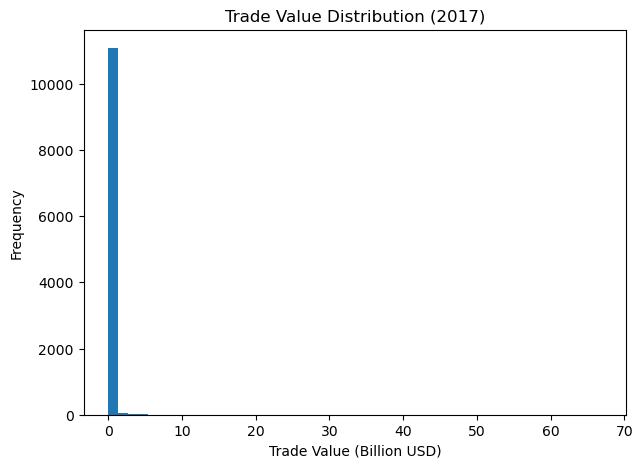


Top 25 Most Central Countries


,Country,Degree,PageRank
6,China,375,0.107
93,"China, Hong Kong SAR",267,0.098
20,USA,353,0.061
13,Singapore,294,0.054
11,Rep. of Korea,283,0.046
30,Malaysia,245,0.044
26,Germany,310,0.043
62,"Other Asia, nes",285,0.035
33,Netherlands,322,0.030
8,France,339,0.021




YEAR : 2018

Top 25 Exporters


exporter
Other Asia, nes         140.999
Rep. of Korea           138.475
China                   127.523
Malaysia                 94.751
Singapore                54.806
USA                      49.517
Japan                    46.109
Philippines              43.659
Germany                  22.083
Viet Nam                 17.639
Thailand                 16.103
Ireland                   9.445
Mexico                    6.959
China, Hong Kong SAR      6.868
Netherlands               6.685
France                    6.502
United Kingdom            3.417
Italy                     2.924
Israel                    2.430
Austria                   2.261
Canada                    1.407
Indonesia                 1.253
Czechia                   1.120
Switzerland               1.105
Hungary                   1.051
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China                   182.480
China, Hong Kong SAR    176.628
Singapore                67.485
Other Asia, nes          46.076
USA                      45.008
Rep. of Korea            38.554
Malaysia                 37.810
Viet Nam                 26.295
Japan                    25.872
Germany                  25.645
Mexico                   23.524
Netherlands              16.180
Philippines              14.952
Thailand                 13.260
India                    10.951
France                    5.730
Brazil                    5.682
Czechia                   4.413
Hungary                   4.095
Poland                    3.252
United Kingdom            3.043
Italy                     2.815
Canada                    2.624
Indonesia                 2.485
Australia                 2.191
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
201659,Rep. of Korea,China,66.832
195372,China,"China, Hong Kong SAR",46.054
200890,"Other Asia, nes",China,33.288
200891,"Other Asia, nes","China, Hong Kong SAR",29.956
202376,Singapore,"China, Hong Kong SAR",26.520
201660,Rep. of Korea,"China, Hong Kong SAR",25.444
200995,"Other Asia, nes",Singapore,23.504
199516,Malaysia,China,22.555
199517,Malaysia,"China, Hong Kong SAR",16.806
199636,Malaysia,USA,16.038


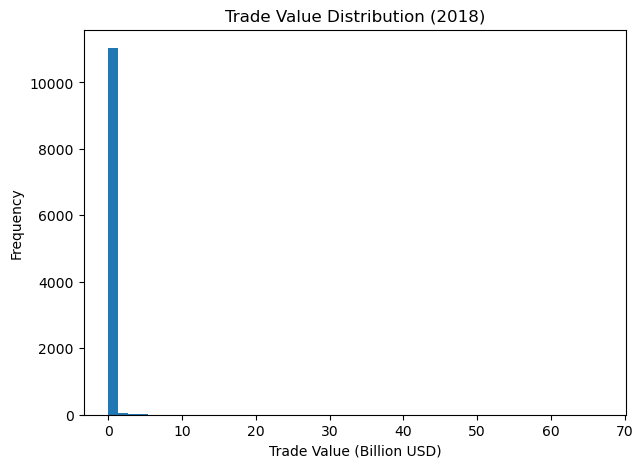


Top 25 Most Central Countries


,Country,Degree,PageRank
67,"China, Hong Kong SAR",274,0.098
7,China,367,0.096
23,USA,354,0.064
18,Singapore,318,0.052
11,Germany,328,0.046
81,India,269,0.041
44,Malaysia,247,0.039
17,Rep. of Korea,302,0.039
75,"Other Asia, nes",270,0.034
14,Netherlands,315,0.027




YEAR : 2019

Top 25 Exporters


exporter
Other Asia, nes         141.013
China                   139.408
Rep. of Korea           111.694
Malaysia                 99.102
Singapore                51.949
USA                      49.077
Japan                    46.627
Philippines              28.039
Viet Nam                 26.361
Germany                  20.453
Thailand                 16.004
Ireland                  12.007
China, Hong Kong SAR      7.966
Netherlands               7.638
France                    7.169
Mexico                    6.796
United Kingdom            2.932
Italy                     2.825
Israel                    2.490
Austria                   2.042
Canada                    1.798
Belgium                   1.204
Czechia                   1.142
Switzerland               1.116
Hungary                   1.071
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China                   174.055
China, Hong Kong SAR    165.610
Singapore                64.264
Other Asia, nes          47.554
USA                      45.125
Rep. of Korea            39.653
Malaysia                 34.041
Viet Nam                 33.961
Mexico                   25.861
Japan                    23.450
Germany                  21.301
Netherlands              15.937
Philippines              15.319
India                    13.418
Thailand                 12.041
Brazil                    5.709
France                    5.174
Hungary                   4.404
Czechia                   3.757
Poland                    3.180
Belgium                   3.071
United Kingdom            2.747
Italy                     2.617
Spain                     2.541
Indonesia                 2.267
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
212780,Rep. of Korea,China,49.684
206471,China,"China, Hong Kong SAR",49.273
211966,"Other Asia, nes",China,35.014
211967,"Other Asia, nes","China, Hong Kong SAR",30.098
213529,Singapore,"China, Hong Kong SAR",25.405
210588,Malaysia,China,25.150
212076,"Other Asia, nes",Singapore,24.173
212781,Rep. of Korea,"China, Hong Kong SAR",18.076
210702,Malaysia,USA,17.726
206581,China,Rep. of Korea,16.701


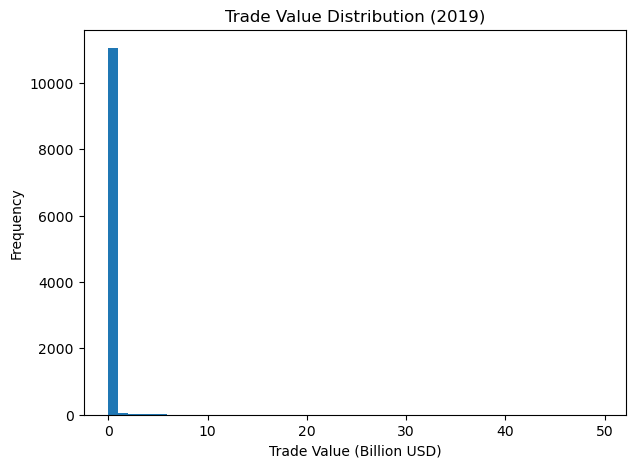


Top 25 Most Central Countries


,Country,Degree,PageRank
3,China,372,0.100
110,"China, Hong Kong SAR",280,0.096
17,USA,348,0.065
77,India,271,0.052
13,Singapore,292,0.042
23,Germany,333,0.041
12,Rep. of Korea,283,0.038
39,Malaysia,244,0.033
9,"Other Asia, nes",279,0.033
29,Netherlands,306,0.026




YEAR : 2020

Top 25 Exporters


exporter
Other Asia, nes         166.912
China                   148.217
Rep. of Korea           120.274
Malaysia                100.307
Singapore                58.329
Japan                    55.892
USA                      50.615
Viet Nam                 35.309
Philippines              27.907
Germany                  18.730
Thailand                 17.803
Ireland                  10.169
Mexico                    7.803
Netherlands               7.516
China, Hong Kong SAR      6.791
France                    6.772
Israel                    4.514
United Kingdom            2.906
Italy                     2.768
Belgium                   1.813
Austria                   1.720
Costa Rica                1.248
Canada                    1.193
Switzerland               1.127
Czechia                   0.973
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China                   206.127
China, Hong Kong SAR    183.787
Singapore                74.185
Other Asia, nes          55.651
USA                      46.432
Rep. of Korea            44.261
Viet Nam                 40.169
Malaysia                 33.860
Japan                    23.194
Mexico                   22.961
Germany                  19.483
Netherlands              16.157
Philippines              14.959
Thailand                 12.455
India                    10.629
France                    5.272
Brazil                    4.848
Poland                    4.536
Hungary                   4.051
Czechia                   3.636
Belgium                   3.247
United Kingdom            2.664
Italy                     2.594
Indonesia                 2.352
Spain                     2.139
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
223762,Rep. of Korea,China,54.109
217599,China,"China, Hong Kong SAR",52.132
222949,"Other Asia, nes",China,44.718
222950,"Other Asia, nes","China, Hong Kong SAR",38.326
224483,Singapore,"China, Hong Kong SAR",30.089
223056,"Other Asia, nes",Singapore,29.420
221656,Malaysia,China,25.309
223763,Rep. of Korea,"China, Hong Kong SAR",18.094
217709,China,Rep. of Korea,17.978
220929,Japan,China,17.259


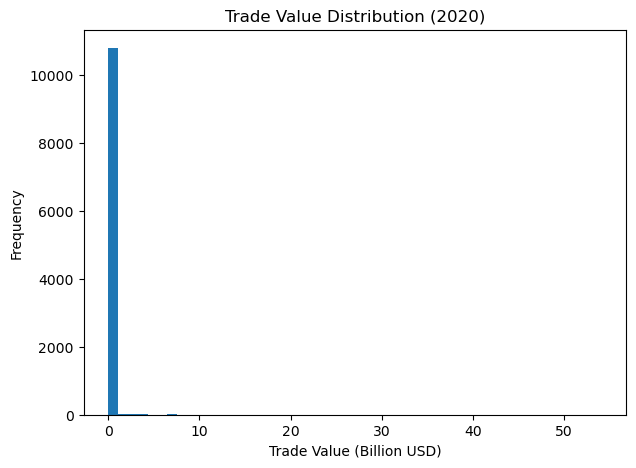


Top 25 Most Central Countries


,Country,Degree,PageRank
2,China,361,0.104
110,"China, Hong Kong SAR",264,0.103
17,USA,349,0.064
32,Singapore,313,0.048
45,India,260,0.043
25,Germany,322,0.039
39,Rep. of Korea,286,0.038
46,"Other Asia, nes",268,0.036
28,Malaysia,232,0.035
164,Viet Nam,201,0.028




YEAR : 2021

Top 25 Exporters


exporter
Other Asia, nes         215.027
China                   197.837
Rep. of Korea           155.813
Malaysia                 95.825
Singapore                72.806
Japan                    66.059
USA                      55.028
Philippines              33.806
Viet Nam                 31.605
Germany                  23.688
Thailand                 20.042
Ireland                  18.888
China, Hong Kong SAR      9.686
Netherlands               9.619
France                    8.180
Israel                    7.893
Mexico                    4.311
Italy                     3.333
Austria                   2.287
Costa Rica                2.157
United Kingdom            2.042
Belgium                   1.599
Switzerland               1.324
Czechia                   1.313
Canada                    1.205
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China, Hong Kong SAR    238.837
China                   235.858
Singapore                96.492
Other Asia, nes          71.785
Rep. of Korea            55.073
Viet Nam                 49.760
Malaysia                 42.064
USA                      36.328
Japan                    28.337
Germany                  22.988
Mexico                   21.795
Netherlands              18.725
India                    17.482
Thailand                 15.280
Philippines              15.025
Brazil                    7.904
Poland                    5.948
France                    5.860
Ireland                   5.793
Hungary                   4.782
Italy                     3.875
Belgium                   3.765
United Kingdom            3.749
Czechia                   3.431
Indonesia                 3.382
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
228568,China,"China, Hong Kong SAR",72.619
235027,Rep. of Korea,China,69.359
234213,"Other Asia, nes","China, Hong Kong SAR",52.574
234212,"Other Asia, nes",China,52.427
234318,"Other Asia, nes",Singapore,41.234
235803,Singapore,"China, Hong Kong SAR",40.424
232809,Malaysia,China,27.501
235028,Rep. of Korea,"China, Hong Kong SAR",24.588
228678,China,Rep. of Korea,22.753
228667,China,"Other Asia, nes",22.183


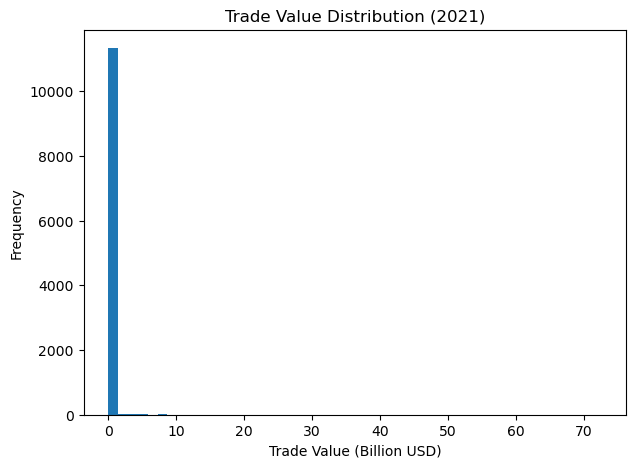


Top 25 Most Central Countries


,Country,Degree,PageRank
63,"China, Hong Kong SAR",263,0.107
4,China,374,0.100
50,USA,351,0.054
73,India,279,0.048
14,Singapore,309,0.048
6,Germany,346,0.039
44,Malaysia,245,0.038
12,Rep. of Korea,295,0.037
10,"Other Asia, nes",270,0.036
8,Netherlands,328,0.028




YEAR : 2022

Top 25 Exporters


exporter
Other Asia, nes         259.396
China                   229.372
Rep. of Korea           164.680
Malaysia                107.494
Singapore                74.108
Japan                    67.040
USA                      53.631
Philippines              39.183
Viet Nam                 33.934
Thailand                 29.340
Germany                  27.244
Ireland                  17.368
China, Hong Kong SAR     11.779
Israel                   11.656
Netherlands              10.407
France                   10.357
Mexico                    6.704
Italy                     3.841
United Kingdom            2.942
Austria                   2.802
Belgium                   1.922
Costa Rica                1.777
Canada                    1.496
Malta                     1.484
Czechia                   1.436
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China                   243.034
China, Hong Kong SAR    236.798
Singapore               110.016
Other Asia, nes          75.675
Rep. of Korea            65.412
USA                      59.472
Viet Nam                 56.698
Malaysia                 51.624
Japan                    37.320
Germany                  35.638
Mexico                   27.234
Thailand                 19.507
India                    19.341
Philippines              19.125
Netherlands              12.749
Brazil                   10.010
France                    8.026
Poland                    6.760
Ireland                   6.580
Belgium                   5.880
Hungary                   5.724
Spain                     5.658
Italy                     5.385
Indonesia                 4.987
United Kingdom            4.755
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
240034,China,"China, Hong Kong SAR",71.237
246547,Rep. of Korea,China,68.160
245731,"Other Asia, nes",China,60.373
245732,"Other Asia, nes","China, Hong Kong SAR",58.659
245840,"Other Asia, nes",Singapore,45.490
247297,Singapore,"China, Hong Kong SAR",38.377
244320,Malaysia,China,26.464
240143,China,Rep. of Korea,25.454
240132,China,"Other Asia, nes",22.798
245828,"Other Asia, nes",Rep. of Korea,19.596


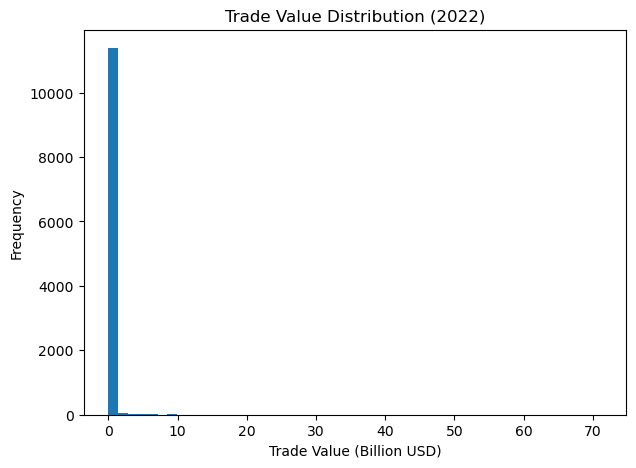


Top 25 Most Central Countries


,Country,Degree,PageRank
2,China,368,0.096
108,"China, Hong Kong SAR",258,0.091
38,USA,360,0.064
27,Germany,346,0.052
9,Singapore,300,0.043
73,India,278,0.039
6,Malaysia,249,0.039
56,"Other Asia, nes",273,0.036
8,Rep. of Korea,285,0.034
5,Japan,267,0.024




YEAR : 2023

Top 25 Exporters


exporter
Other Asia, nes         232.347
China                   216.541
Rep. of Korea           132.665
Malaysia                 89.078
Japan                    63.201
Singapore                61.228
USA                      42.965
Viet Nam                 36.237
Philippines              32.105
Germany                  28.437
Thailand                 27.732
Ireland                  14.323
Israel                   11.800
Netherlands              10.753
France                   10.706
Mexico                    6.000
China, Hong Kong SAR      4.868
Italy                     3.841
Austria                   3.062
Costa Rica                2.855
Cambodia                  2.735
India                     2.439
Belgium                   2.082
United Kingdom            1.837
Morocco                   1.641
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China, Hong Kong SAR    215.966
China                   194.637
Singapore                89.810
Other Asia, nes          61.456
USA                      61.192
Rep. of Korea            55.452
Viet Nam                 51.234
Malaysia                 44.126
Germany                  36.238
Japan                    33.738
Mexico                   27.419
India                    25.274
Thailand                 20.983
Philippines              14.754
Netherlands              11.433
Brazil                    9.194
France                    7.579
Belgium                   7.064
Hungary                   6.080
Italy                     5.783
Poland                    5.382
Ireland                   4.954
Indonesia                 4.901
United Kingdom            4.864
Spain                     4.789
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
251537,China,"China, Hong Kong SAR",72.526
257292,"Other Asia, nes","China, Hong Kong SAR",51.796
258107,Rep. of Korea,China,50.812
257291,"Other Asia, nes",China,49.589
257387,"Other Asia, nes",Singapore,38.112
258810,Singapore,"China, Hong Kong SAR",30.039
255887,Malaysia,China,20.679
251648,China,Rep. of Korea,18.589
255050,Japan,China,18.473
251637,China,"Other Asia, nes",18.243


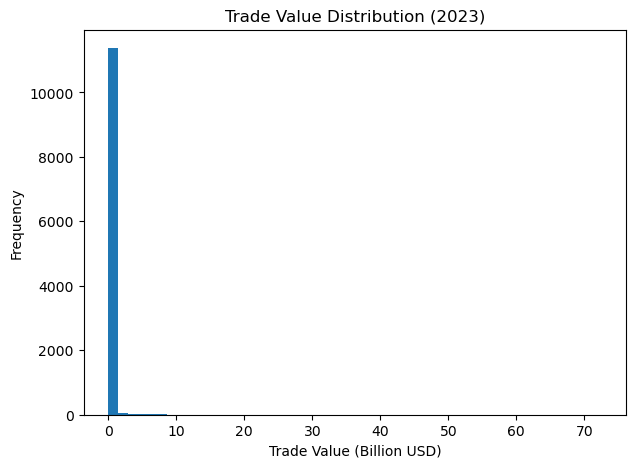


Top 25 Most Central Countries


,Country,Degree,PageRank
2,China,363,0.094
83,"China, Hong Kong SAR",266,0.092
40,USA,345,0.072
6,Germany,347,0.048
37,Singapore,305,0.043
11,Rep. of Korea,284,0.043
9,Malaysia,257,0.042
44,"Other Asia, nes",262,0.035
168,Viet Nam,197,0.028
65,Japan,254,0.025




YEAR : 2024

Top 25 Exporters


exporter
Other Asia, nes         241.744
China                   228.876
Rep. of Korea           172.274
Malaysia                 94.301
Singapore                75.895
Japan                    62.102
USA                      46.926
Viet Nam                 40.021
Philippines              26.498
Germany                  23.596
Thailand                 21.785
Ireland                  14.092
China, Hong Kong SAR     13.287
Israel                   13.022
France                    7.690
Netherlands               7.384
Mexico                    4.482
Costa Rica                4.226
Italy                     3.899
Austria                   2.776
India                     2.303
United Kingdom            1.901
Belgium                   1.812
Morocco                   1.704
Cambodia                  1.601
Name: Trade Value (Billion USD), dtype: float64


Top 25 Importers


importer
China, Hong Kong SAR    238.928
China                   214.839
Singapore                99.152
Other Asia, nes          78.767
Viet Nam                 66.028
Rep. of Korea            64.363
USA                      62.277
Malaysia                 52.667
India                    28.985
Mexico                   28.168
Japan                    27.424
Germany                  26.020
Thailand                 23.957
Philippines              14.521
Brazil                    9.212
Netherlands               7.919
France                    6.361
Hungary                   5.082
Ireland                   5.079
Poland                    4.737
Indonesia                 4.542
Czechia                   4.127
Belgium                   3.991
Italy                     3.678
Spain                     3.546
Name: Trade Value (Billion USD), dtype: float64


Top 25 Bilateral Trade Flows


,exporter,importer,Trade Value (Billion USD)
262961,China,"China, Hong Kong SAR",83.604
269110,Rep. of Korea,China,64.410
268341,"Other Asia, nes",China,50.593
268342,"Other Asia, nes","China, Hong Kong SAR",47.770
268432,"Other Asia, nes",Singapore,45.919
269801,Singapore,"China, Hong Kong SAR",36.751
269187,Rep. of Korea,"Other Asia, nes",28.971
269111,Rep. of Korea,"China, Hong Kong SAR",22.765
268424,"Other Asia, nes",Rep. of Korea,22.584
263071,China,Rep. of Korea,21.010


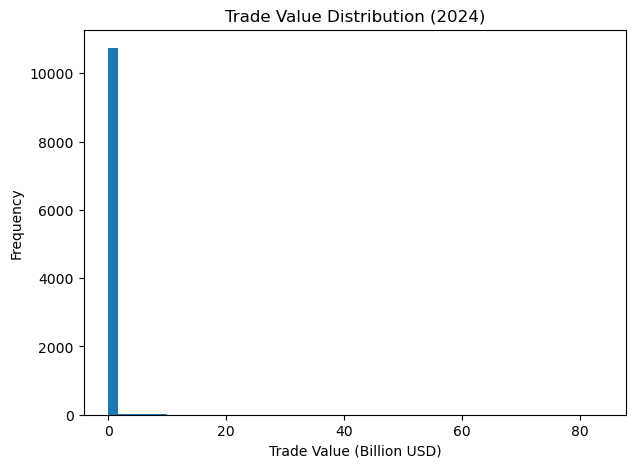


Top 25 Most Central Countries


,Country,Degree,PageRank
22,China,358,0.103
84,"China, Hong Kong SAR",251,0.103
161,Viet Nam,159,0.080
43,USA,326,0.075
10,Malaysia,259,0.039
6,Germany,345,0.037
14,Singapore,296,0.037
102,"Other Asia, nes",244,0.036
13,Rep. of Korea,276,0.036
89,Japan,236,0.024


In [14]:
# ==========================================================
# Cell 5.1 : Trade Network Analysis
# ==========================================================

print("=" * 70)
print("Trade Network Analysis")
print("=" * 70)

for year in years:

    print("\n")
    print("=" * 70)
    print(f"YEAR : {year}")
    print("=" * 70)

    yearly = edge_features[
        edge_features["year"] == year
    ].copy()

    # ------------------------------------------------------
    # Top Exporters
    # ------------------------------------------------------

    top_exporters = (
        yearly
        .groupby("exporter")["total_trade_value"]
        .sum()
        .div(1_000_000)                       # Convert to Billion USD, BACI dataset had already been in thousand usd dollars
        .round(3)                             # 3 decimals
        .sort_values(ascending=False)
        .head(25)
        .rename("Trade Value (Billion USD)")
    )

    print("\nTop 25 Exporters")
    display(top_exporters)

    # ------------------------------------------------------
    # Top Importers
    # ------------------------------------------------------

    top_importers = (
        yearly
        .groupby("importer")["total_trade_value"]
        .sum()
        .div(1_000_000)
        .round(3)
        .sort_values(ascending=False)
        .head(25)
        .rename("Trade Value (Billion USD)")
    )

    print("\nTop 25 Importers")
    display(top_importers)

    # ------------------------------------------------------
    # Top Bilateral Trade Flows
    # ------------------------------------------------------

    top_flows = (
        yearly[
            [
                "exporter",
                "importer",
                "total_trade_value"
            ]
        ]
        .assign(
            **{
                "Trade Value (Billion USD)":
                lambda x: (
                    x["total_trade_value"] / 1_000_000
                ).round(3)
            }
        )
        .drop(columns="total_trade_value")
        .sort_values(
            by="Trade Value (Billion USD)",
            ascending=False
        )
        .head(25)
    )

    print("\nTop 25 Bilateral Trade Flows")
    display(top_flows)

    # ------------------------------------------------------
    # Edge Weight Distribution
    # ------------------------------------------------------

    plt.figure(figsize=(7,5))

    plt.hist(
        yearly["total_trade_value"] / 1_000_000,
        bins=50
    )

    plt.xlabel("Trade Value (Billion USD)")

    plt.ylabel("Frequency")

    plt.title(
        f"Trade Value Distribution ({year})"
    )

    plt.show()

    # ------------------------------------------------------
    # Network Centrality
    # ------------------------------------------------------

    G = graphs[year]

    pagerank = nx.pagerank(
        G,
        weight="weight"
    )

    degree = dict(G.degree())

    centrality = pd.DataFrame({

        "Country": list(G.nodes()),

        "Degree":
            [degree[n] for n in G.nodes()],

        "PageRank":
            [round(pagerank[n], 3) for n in G.nodes()]

    })

    centrality = centrality.sort_values(
        "PageRank",
        ascending=False
    )

    print("\nTop 25 Most Central Countries")

    display(
        centrality.head(25)
    )

In [15]:
# ==========================================================
# Cell 5.2 : Network Centrality Analysis
# ==========================================================

print("=" * 70)
print("Network Centrality Analysis")
print("=" * 70)

centrality_results = {}

for year, G in graphs.items():

    print("\n")
    print("=" * 70)
    print(f"YEAR : {year}")
    print("=" * 70)

    # ------------------------------------------------------
    # Centrality Measures
    # ------------------------------------------------------

    degree = nx.degree_centrality(G)

    betweenness = nx.betweenness_centrality(
        G,
        normalized=True
    )

    closeness = nx.closeness_centrality(G)

    pagerank = nx.pagerank(
        G,
        weight="weight"
    )

    eigenvector = nx.eigenvector_centrality(
        G,
        max_iter=500
    )

    centrality = pd.DataFrame({

        "Country": list(G.nodes()),

        "Degree Centrality":
            [degree[n] for n in G.nodes()],

        "Betweenness":
            [betweenness[n] for n in G.nodes()],

        "Closeness":
            [closeness[n] for n in G.nodes()],

        "Eigenvector":
            [eigenvector[n] for n in G.nodes()],

        "PageRank":
            [pagerank[n] for n in G.nodes()]

    })

    # Sort by PageRank
    centrality = centrality.sort_values(
        by="PageRank",
        ascending=False
    )

    # Round all decimal columns to 3 decimals
    centrality = centrality.round(3)

    # Save results
    centrality_results[year] = centrality

    print("Top 25 Most Influential Countries")

    display(
        centrality.head(25)
    )

Network Centrality Analysis


YEAR : 1995
Top 25 Most Influential Countries


,Country,Degree Centrality,Betweenness,Closeness,Eigenvector,PageRank
17,USA,1.285,0.161,0.620,0.177,0.168
91,Singapore,0.816,0.027,0.523,0.134,0.069
9,Germany,1.150,0.079,0.570,0.168,0.054
32,Malaysia,0.696,0.026,0.513,0.127,0.053
26,"China, Hong Kong SAR",0.725,0.008,0.514,0.133,0.052
31,Japan,0.932,0.035,0.536,0.143,0.046
19,United Kingdom,1.217,0.108,0.572,0.162,0.044
80,"Other Asia, nes",0.551,0.002,0.488,0.106,0.041
38,Rep. of Korea,0.686,0.014,0.518,0.130,0.036
30,France,1.053,0.069,0.554,0.157,0.029




YEAR : 1996
Top 25 Most Influential Countries


,Country,Degree Centrality,Betweenness,Closeness,Eigenvector,PageRank
16,USA,1.340,0.163,0.662,0.178,0.166
42,Singapore,0.890,0.031,0.556,0.135,0.069
34,Japan,0.871,0.026,0.551,0.126,0.056
59,"China, Hong Kong SAR",0.732,0.007,0.537,0.121,0.051
8,Germany,1.225,0.104,0.627,0.171,0.048
35,Malaysia,0.713,0.020,0.551,0.127,0.048
13,Rep. of Korea,0.761,0.029,0.556,0.128,0.046
51,United Kingdom,1.196,0.105,0.583,0.149,0.046
38,"Other Asia, nes",0.593,0.002,0.523,0.109,0.043
7,France,1.129,0.079,0.595,0.153,0.030




YEAR : 1997
Top 25 Most Influential Countries


...

,Country,Degree Centrality,Betweenness,Closeness,Eigenvector,PageRank
2,China,1.636,0.064,0.787,0.138,0.096
108,"China, Hong Kong SAR",1.147,0.007,0.623,0.097,0.091
38,USA,1.600,0.068,0.779,0.133,0.064
27,Germany,1.538,0.041,0.779,0.138,0.052
9,Singapore,1.333,0.032,0.717,0.118,0.043
73,India,1.236,0.017,0.652,0.103,0.039
6,Malaysia,1.107,0.011,0.643,0.103,0.039
56,"Other Asia, nes",1.213,0.014,0.658,0.106,0.036
8,Rep. of Korea,1.267,0.019,0.699,0.117,0.034
5,Japan,1.187,0.013,0.666,0.109,0.024




YEAR : 2023
Top 25 Most Influential Countries


,Country,Degree Centrality,Betweenness,Closeness,Eigenvector,PageRank
2,China,1.613,0.055,0.765,0.138,0.094
83,"China, Hong Kong SAR",1.182,0.011,0.636,0.102,0.092
40,USA,1.533,0.054,0.753,0.130,0.072
6,Germany,1.542,0.046,0.763,0.138,0.048
11,Rep. of Korea,1.262,0.023,0.703,0.119,0.043
37,Singapore,1.356,0.039,0.728,0.123,0.043
9,Malaysia,1.142,0.016,0.656,0.106,0.042
44,"Other Asia, nes",1.164,0.015,0.650,0.101,0.035
168,Viet Nam,0.876,0.002,0.592,0.081,0.028
65,Japan,1.129,0.010,0.650,0.106,0.025




YEAR : 2024
Top 25 Most Influential Countries


,Country,Degree Centrality,Betweenness,Closeness,Eigenvector,PageRank
22,China,1.591,0.066,0.756,0.136,0.103
84,"China, Hong Kong SAR",1.116,0.011,0.628,0.103,0.103
161,Viet Nam,0.707,0.000,0.566,0.071,0.080
43,USA,1.449,0.048,0.726,0.128,0.075
10,Malaysia,1.151,0.011,0.652,0.112,0.039
6,Germany,1.533,0.052,0.764,0.141,0.037
14,Singapore,1.316,0.044,0.719,0.122,0.037
102,"Other Asia, nes",1.084,0.012,0.634,0.101,0.036
13,Rep. of Korea,1.227,0.031,0.695,0.119,0.036
89,Japan,1.049,0.010,0.645,0.109,0.024


In [16]:
# Cell 5.3 : Community Detection

from networkx.algorithms.community import louvain_communities

print("=" * 70)
print("Community Detection")
print("=" * 70)

community_statistics = []

communities_results = {}

for year, G in graphs.items():

    print("\n")
    print("=" * 70)
    print(f"YEAR : {year}")
    print("=" * 70)

    G_undirected = G.to_undirected()

    communities = louvain_communities(
        G_undirected,
        weight="weight",
        seed=42
    )

    modularity = nx.community.modularity(
        G_undirected,
        communities,
        weight="weight"
    )

    communities_results[year] = communities

    sizes = [len(c) for c in communities]

    stats = {

        "Year": year,

        "Number of Communities":
            len(communities),

        "Largest Community":
            max(sizes),

        "Smallest Community":
            min(sizes),

        "Average Community Size":
            np.mean(sizes),

        "Modularity":
            modularity

    }

    community_statistics.append(stats)

    print(f"Detected Communities : {len(communities)}")

    print(f"Modularity Score     : {modularity:.4f}")

community_statistics = pd.DataFrame(
    community_statistics
)

print("\n")

display(
    community_statistics
)

Community Detection


YEAR : 1995
Detected Communities : 3
Modularity Score     : 0.1618


YEAR : 1996
Detected Communities : 3
Modularity Score     : 0.1456


YEAR : 1997
Detected Communities : 3
Modularity Score     : 0.1431


YEAR : 1998
Detected Communities : 3
Modularity Score     : 0.1171


YEAR : 1999
Detected Communities : 3
Modularity Score     : 0.1425


YEAR : 2000
Detected Communities : 4
Modularity Score     : 0.1783


YEAR : 2001
Detected Communities : 4
Modularity Score     : 0.1640


YEAR : 2002
Detected Communities : 3
Modularity Score     : 0.1360


YEAR : 2003
Detected Communities : 3
Modularity Score     : 0.1741


YEAR : 2004
Detected Communities : 4
Modularity Score     : 0.1329


YEAR : 2005
Detected Communities : 3
Modularity Score     : 0.1546


YEAR : 2006
Detected Communities : 4
Modularity Score     : 0.1201


YEAR : 2007
Detected Communities : 4
Modularity Score     : 0.1513


YEAR : 2008
Detected Communities : 3
Modularity Score     : 0.1264


YEAR : 2009


,Year,Number of Communities,Largest Community,Smallest Community,Average Community Size,Modularity
0,1995,3,113,47,69.333333,0.161798
1,1996,3,123,42,70.000000,0.145570
2,1997,3,124,40,69.000000,0.143127
3,1998,3,116,28,69.000000,0.117097
4,1999,3,109,51,70.666667,0.142457
5,2000,4,101,22,55.500000,0.178276
6,2001,4,108,22,55.500000,0.163962
7,2002,3,104,31,74.000000,0.135966
8,2003,3,129,38,74.000000,0.174055
9,2004,4,133,18,55.500000,0.132910


Temporal Evolution of the Trade Network


,Year,Nodes,Edges,Density,Average Degree,Average Clustering,Connected Components,Number of Communities,Largest Community,Smallest Community,Average Community Size,Modularity
0,1995,208,4315,0.100,41.490,0.813,1,3,113,47,69.333,0.162
1,1996,210,4699,0.107,44.752,0.836,1,3,123,42,70.000,0.146
2,1997,207,5034,0.118,48.638,0.830,1,3,124,40,69.000,0.143
3,1998,207,5311,0.125,51.314,0.847,1,3,116,28,69.000,0.117
4,1999,212,5736,0.128,54.113,0.848,1,3,109,51,70.667,0.142
5,2000,222,6968,0.142,62.775,0.844,1,4,101,22,55.500,0.178
6,2001,222,7314,0.149,65.892,0.821,1,4,108,22,55.500,0.164
7,2002,222,7476,0.152,67.351,0.844,1,3,104,31,74.000,0.136
8,2003,222,7866,0.160,70.865,0.843,1,3,129,38,74.000,0.174
9,2004,222,8308,0.169,74.847,0.830,1,4,133,18,55.500,0.133


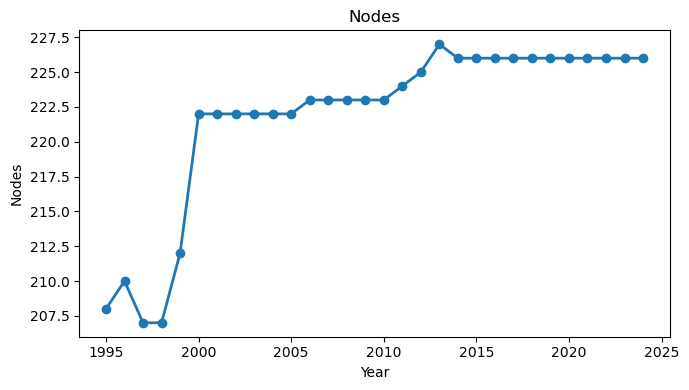

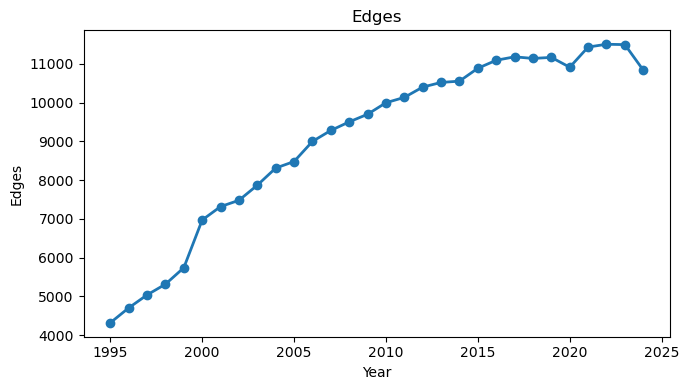

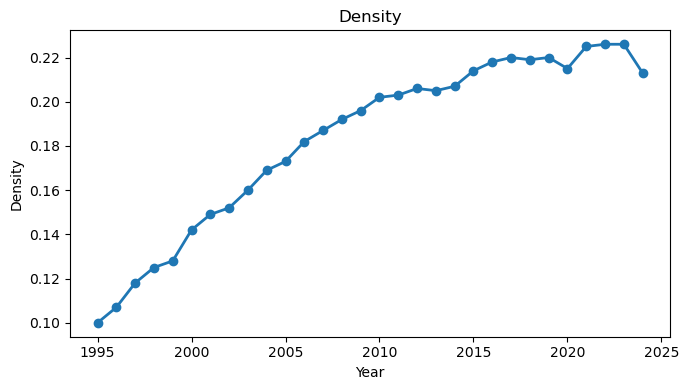

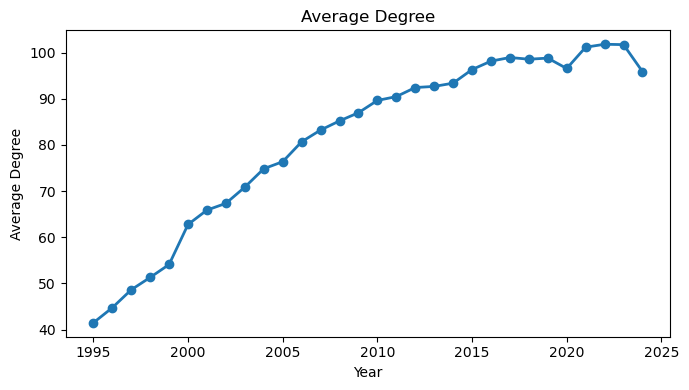

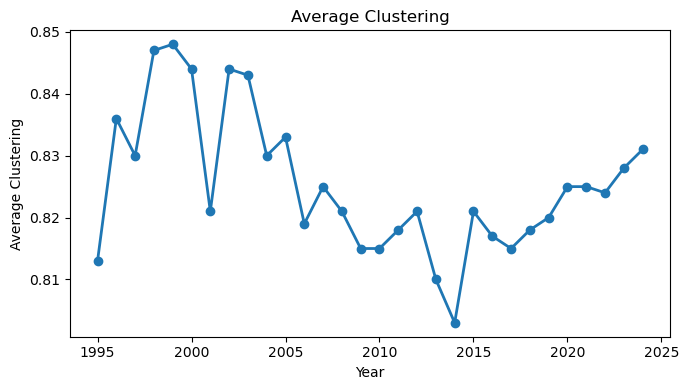

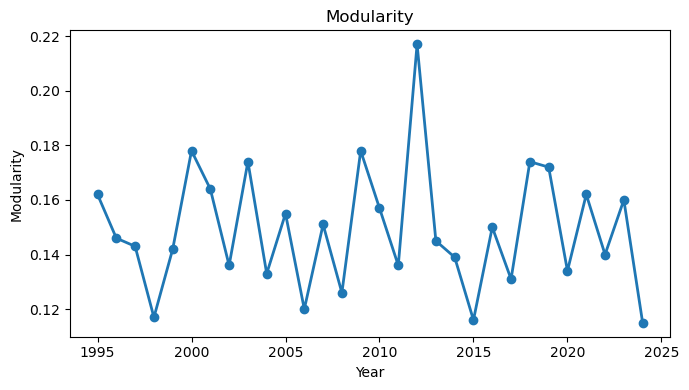

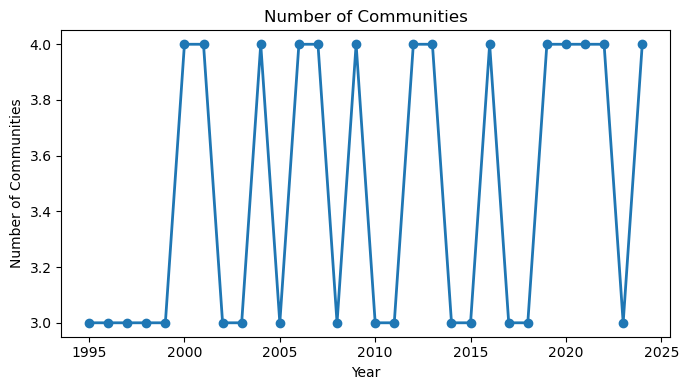

In [17]:
# ==========================================================
# Cell 5.4 : Temporal Evolution of the Trade Network
# ==========================================================

print("=" * 70)
print("Temporal Evolution of the Trade Network")
print("=" * 70)

temporal_results = graph_statistics.merge(

    community_statistics,

    on="Year"

)

# Round all decimal columns to 3 decimals
temporal_results = temporal_results.round(3)

display(
    temporal_results
)

# ----------------------------------------------------------
# Evolution plots
# ----------------------------------------------------------

metrics = [

    "Nodes",

    "Edges",

    "Density",

    "Average Degree",

    "Average Clustering",

    "Modularity",

    "Number of Communities"

]

for metric in metrics:

    plt.figure(figsize=(7,4))

    plt.plot(

        temporal_results["Year"],

        temporal_results[metric],

        marker="o",

        linewidth=2

    )

    plt.title(metric)

    plt.xlabel("Year")

    plt.ylabel(metric)

    plt.grid(False)

    plt.tight_layout()

    plt.show()

In [18]:
# ============================
# Save temporal_results 
# ============================

filename_csv = "InternationalTrade_SemiConductor_Temporal Evolution of the Trade Network_1995_2024.csv"

temporal_results.to_csv(filename_csv, index=False)

print(f"World Semiconductor temporal_results successfully saved as:\n{filename_csv}")

World Semiconductor temporal_results successfully saved as:
InternationalTrade_SemiConductor_Temporal Evolution of the Trade Network_1995_2024.csv


In [19]:
temporal_results

,Year,Nodes,Edges,Density,Average Degree,Average Clustering,Connected Components,Number of Communities,Largest Community,Smallest Community,Average Community Size,Modularity
0,1995,208,4315,0.100,41.490,0.813,1,3,113,47,69.333,0.162
1,1996,210,4699,0.107,44.752,0.836,1,3,123,42,70.000,0.146
2,1997,207,5034,0.118,48.638,0.830,1,3,124,40,69.000,0.143
3,1998,207,5311,0.125,51.314,0.847,1,3,116,28,69.000,0.117
4,1999,212,5736,0.128,54.113,0.848,1,3,109,51,70.667,0.142
5,2000,222,6968,0.142,62.775,0.844,1,4,101,22,55.500,0.178
6,2001,222,7314,0.149,65.892,0.821,1,4,108,22,55.500,0.164
7,2002,222,7476,0.152,67.351,0.844,1,3,104,31,74.000,0.136
8,2003,222,7866,0.160,70.865,0.843,1,3,129,38,74.000,0.174
9,2004,222,8308,0.169,74.847,0.830,1,4,133,18,55.500,0.133


Evolution of Global Semiconductor Trade


,Year,Total Trade (Billion USD),Annual Growth Rate (%)
0,1995,174.589,NaN
1,1996,174.578,-0.006
2,1997,188.462,7.953
3,1998,181.398,-3.749
4,1999,212.690,17.251
5,2000,275.609,29.582
6,2001,226.497,-17.820
7,2002,235.474,3.964
8,2003,275.217,16.878
9,2004,330.302,20.015


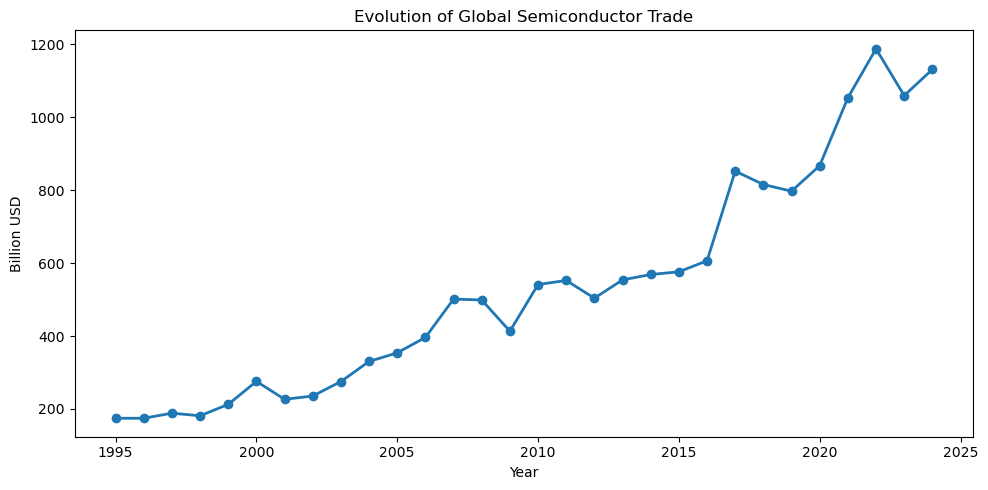

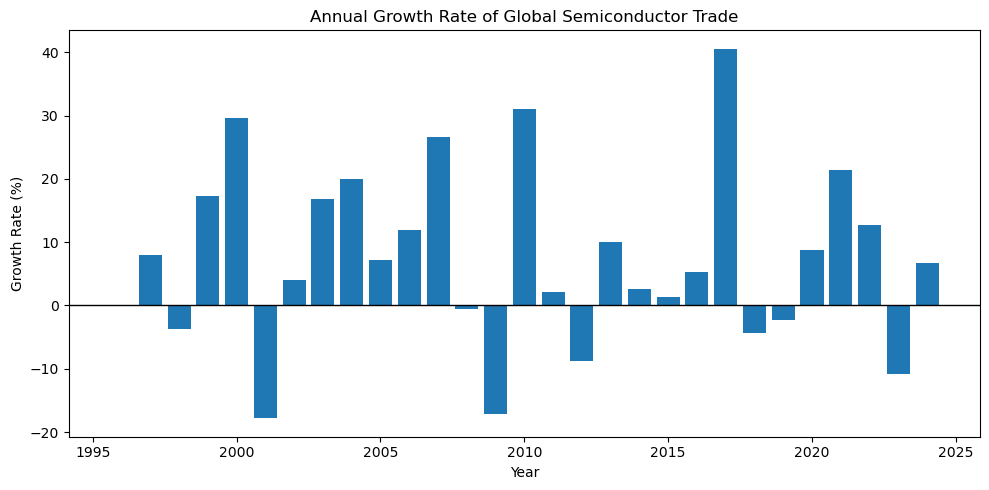

In [20]:
# ==========================================================
# Cell 5.5 : Evolution of Global Semiconductor Trade
# ==========================================================

print("=" * 70)
print("Evolution of Global Semiconductor Trade")
print("=" * 70)

# ----------------------------------------------------------
# Annual Global Trade (Million USD)
# ----------------------------------------------------------

trade_evolution = (
    df
    .groupby("year")["trade_value"]
    .sum()
    .div(1_000_000)          # Convert to Million USD
    .reset_index()
)

trade_evolution.columns = [
    "Year",
    "Total Trade (Billion USD)"
]

# ----------------------------------------------------------
# Annual Growth Rate (%)
# ----------------------------------------------------------

trade_evolution["Annual Growth Rate (%)"] = (
    trade_evolution["Total Trade (Billion USD)"]
    .pct_change()
    * 100
)

# Round all decimal values
trade_evolution = trade_evolution.round(3)

display(trade_evolution)

# ----------------------------------------------------------
# Figure 1 : Evolution of Global Semiconductor Trade
# ----------------------------------------------------------

plt.figure(figsize=(10,5))

plt.plot(
    trade_evolution["Year"],
    trade_evolution["Total Trade (Billion USD)"],
    marker="o",
    linewidth=2
)

plt.title("Evolution of Global Semiconductor Trade")

plt.xlabel("Year")

plt.ylabel("Billion USD")

plt.grid(False)

plt.tight_layout()

plt.show()

# ----------------------------------------------------------
# Figure 2 : Annual Growth Rate
# ----------------------------------------------------------

plt.figure(figsize=(10,5))

plt.bar(
    trade_evolution["Year"],
    trade_evolution["Annual Growth Rate (%)"],
    width=0.8
)

plt.axhline(
    y=0,
    color="black",
    linewidth=1
)

plt.title("Annual Growth Rate of Global Semiconductor Trade")

plt.xlabel("Year")

plt.ylabel("Growth Rate (%)")

plt.grid(False)

plt.tight_layout()

plt.show()

In [21]:
# ============================
# Save trade_evolution 
# ============================

filename_csv = "InternationalTrade_SemiConductor_TradeEvolution_1995_2024.csv"

trade_evolution.to_csv(filename_csv, index=False)

print(f"World Semiconductor Trade evolution successfully saved as:\n{filename_csv}")

World Semiconductor Trade evolution successfully saved as:
InternationalTrade_SemiConductor_TradeEvolution_1995_2024.csv


In [13]:
# ==========================================================
# Cell 7 : Node Feature Engineering
# ==========================================================

node_features = {}

for year, G in graphs.items():

    features = []

    nodes = []

    # pagerank = nx.pagerank(G)
    pagerank = nx.pagerank(
        G,
        weight="weight"
    )

    betweenness = nx.betweenness_centrality(G)

    clustering = nx.clustering(
        G.to_undirected()
    )

    for node in G.nodes():

        nodes.append(node)

        features.append([

            G.in_degree(node),

            G.out_degree(node),

            G.degree(node),

            pagerank[node],

            betweenness[node],

            clustering[node]

        ])

    features = np.array(features)

    scaler = StandardScaler()

    features = scaler.fit_transform(features)

    node_features[year] = {

        "nodes": nodes,

        "features": features

    }

print("Node features successfully created.")

Node features successfully created.


In [14]:
# ==========================================================
# Cell 8 : Edge Feature Engineering
# ==========================================================

edge_vectors = {}

for year in years:

    yearly = edge_features[
        edge_features["year"] == year
    ]

    edge_vectors[year] = yearly[[

        "exporter",

        "importer",

        "total_trade_value",

        "average_trade_value",

        "traded_products",

        "diversification_index"

    ]]

print("Edge features successfully created.")

Edge features successfully created.


In [16]:
# ==========================================================
# Cell 9 : Export Trade Networks to Gephi
# ==========================================================

import os
import networkx as nx
from networkx.algorithms.community import louvain_communities

# ----------------------------------------------------------
# Output folder
# ----------------------------------------------------------

output_folder = "Gephi_Graphs"

os.makedirs(output_folder, exist_ok=True)

print("=" * 70)
print("Exporting Trade Networks for Gephi")
print("=" * 70)

# ----------------------------------------------------------
# Number of main trade partners to keep
# ----------------------------------------------------------

TOP_FLOW_PER_COUNTRY = 5

for year in years:

    print(f"\nProcessing {year}...")

    ########################################################
    # Complete graph
    ########################################################

    G = graphs[year].copy()

    ########################################################
    # Node statistics
    ########################################################

    pagerank = nx.pagerank(
        G,
        weight="weight"
    )

    degree = dict(G.degree())

    degree_centrality = nx.degree_centrality(G)

    betweenness = nx.betweenness_centrality(
        G,
        normalized=True
    )

    closeness = nx.closeness_centrality(G)

    eigenvector = nx.eigenvector_centrality(
        G,
        max_iter=500
    )

    ########################################################
    # Community Detection (Louvain)
    ########################################################

    communities = louvain_communities(
        G.to_undirected(),
        weight="weight",
        seed=42
    )

    community_dict = {}

    for cid, community in enumerate(communities):

        for node in community:

            community_dict[node] = cid

    ########################################################
    # Add node attributes
    ########################################################

    for node in G.nodes():

        G.nodes[node]["Degree"] = degree[node]

        G.nodes[node]["DegreeCentrality"] = degree_centrality[node]

        G.nodes[node]["PageRank"] = pagerank[node]

        G.nodes[node]["Betweenness"] = betweenness[node]

        G.nodes[node]["Closeness"] = closeness[node]

        G.nodes[node]["Eigenvector"] = eigenvector[node]

        G.nodes[node]["Community"] = community_dict[node]

    ########################################################
    # Export complete graph
    ########################################################

    filename = os.path.join(
        output_folder,
        f"Semiconductor_Trade_version2_{year}.gexf"
    )

    nx.write_gexf(G, filename)

    ########################################################
    # Top 25 countries (Weighted PageRank)
    ########################################################

    top25 = sorted(
        pagerank,
        key=pagerank.get,
        reverse=True
    )[:25]

    G_top = G.subgraph(top25).copy()

    ########################################################
    # Export Top25
    ########################################################

    filename = os.path.join(
        output_folder,
        f"Semiconductor_Trade_version2_{year}_Top25.gexf"
    )

    nx.write_gexf(G_top, filename)

    ########################################################
    # Article Graph
    ########################################################

    G_article = nx.DiGraph()

    ########################################################
    # Add Top25 countries
    ########################################################

    G_article.add_nodes_from(top25)

    ########################################################
    # Add Top Incoming / Outgoing Trade Flows
    ########################################################

    for country in top25:

        # ----------------------------------------------
        # Top exports
        # ----------------------------------------------

        outgoing_edges = sorted(

            G.out_edges(country, data=True),

            key=lambda x: x[2]["weight"],

            reverse=True

        )[:TOP_FLOW_PER_COUNTRY]

        # ----------------------------------------------
        # Top imports
        # ----------------------------------------------

        incoming_edges = sorted(

            G.in_edges(country, data=True),

            key=lambda x: x[2]["weight"],

            reverse=True

        )[:TOP_FLOW_PER_COUNTRY]

        # ----------------------------------------------
        # Add outgoing edges
        # ----------------------------------------------

        for u, v, data in outgoing_edges:

            G_article.add_edge(
                u,
                v,
                **data
            )

        # ----------------------------------------------
        # Add incoming edges
        # ----------------------------------------------

        for u, v, data in incoming_edges:

            G_article.add_edge(
                u,
                v,
                **data
            )

    ########################################################
    # Copy node attributes
    ########################################################

    for node in G_article.nodes():

        if node in G.nodes():

            G_article.nodes[node].update(
                G.nodes[node]
            )

    ########################################################
    # Copy edge attributes
    ########################################################

    for u, v in G_article.edges():

        if G.has_edge(u, v):

            G_article[u][v].update(
                G[u][v]
            )

    ########################################################
    # Export Article Graph
    ########################################################

    filename = os.path.join(

        output_folder,

        f"Semiconductor_Trade_version2_{year}_Article.gexf"

    )

    nx.write_gexf(

        G_article,

        filename

    )

    ########################################################
    # Display summary
    ########################################################

    print(f"✓ {year} exported successfully.")

    print(
        f"   Complete Graph : "
        f"{G.number_of_nodes()} nodes | "
        f"{G.number_of_edges()} edges"
    )

    print(
        f"   Top25 Graph    : "
        f"{G_top.number_of_nodes()} nodes | "
        f"{G_top.number_of_edges()} edges"
    )

    print(
        f"   Article Graph  : "
        f"{G_article.number_of_nodes()} nodes | "
        f"{G_article.number_of_edges()} edges"
    )

print("\n")

print("=" * 70)
print("All graphs exported successfully.")
print("=" * 70)

Exporting Trade Networks for Gephi

Processing 1995...
✓ 1995 exported successfully.
   Complete Graph : 208 nodes | 4315 edges
   Top25 Graph    : 25 nodes | 595 edges
   Article Graph  : 27 nodes | 202 edges

Processing 1996...
✓ 1996 exported successfully.
   Complete Graph : 210 nodes | 4699 edges
   Top25 Graph    : 25 nodes | 589 edges
   Article Graph  : 32 nodes | 206 edges

Processing 1997...
✓ 1997 exported successfully.
   Complete Graph : 207 nodes | 5034 edges
   Top25 Graph    : 25 nodes | 597 edges
   Article Graph  : 31 nodes | 203 edges

Processing 1998...
✓ 1998 exported successfully.
   Complete Graph : 207 nodes | 5311 edges
   Top25 Graph    : 25 nodes | 596 edges
   Article Graph  : 36 nodes | 206 edges

Processing 1999...
✓ 1999 exported successfully.
   Complete Graph : 212 nodes | 5736 edges
   Top25 Graph    : 25 nodes | 599 edges
   Article Graph  : 32 nodes | 206 edges

Processing 2000...
✓ 2000 exported successfully.
   Complete Graph : 222 nodes | 6968 edg